# Vehicle Classification with MobileNetV2 Transfer Learning
## Fixing misclassifications with class balancing and Albumentations augmentation

**Goal.** Fine-tune an ImageNet-pretrained MobileNetV2 on a multi-class vehicle dataset, then measure whether
**class balancing + Albumentations augmentation** actually reduces misclassifications compared with training
**without augmentation**.

### Experimental design

| ID | Experiment | Class balancing | Augmentation | Role |
|----|-----------|-----------------|--------------|------|
| A | `A_no_aug_imbalanced` | none (natural distribution) | none | Reference: shows the effect of imbalance |
| B | `B_no_aug_balanced` | balanced sampler | **none** | **BEFORE** augmentation |
| C | `C_aug_balanced` | balanced sampler | **Albumentations** (stronger for minority classes) | **AFTER** augmentation |

B and C differ **only** in augmentation, so any change between them is caused by augmentation.

### Contents
1. Setup and configuration
2. Transfer-learning guard (the notebook stops if pretrained weights are missing)
3. Data loading and class distribution
4. Albumentations pipelines
5. Class balancing (with proof that every class is sampled equally)
6. Model and training engine
7. Run experiments (with and without augmentation)
8. Results comparison
9. Misclassification analysis: before vs after augmentation
10. Conclusion and export

> **Kaggle checklist:** Accelerator = GPU (T4 / P100) · dataset attached · your `mobilenet-v2` PyTorch model attached via *Add Input → Models*.

---
## 1. Setup and configuration
All hyper-parameters live in this one cell so every experiment uses identical settings.

In [ ]:
# =====================================================================
# 1. IMPORTS & CONFIGURATION
# =====================================================================
import os, json, random, time, zipfile, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models

try:
    import albumentations as A
    from albumentations.pytorch import ToTensorV2
except ImportError as error:
    raise ImportError(
        "albumentations is not installed. On Kaggle it is normally pre-installed. "
        "If it is missing, turn Internet ON and run: !pip install albumentations"
    ) from error

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
    precision_recall_fscore_support, confusion_matrix, classification_report,
)
from scipy.stats import binomtest
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ---------------- paths ----------------
DATA_ROOT = "/kaggle/input/datasets/muhammadghulamabbas/vehicle/hj3vvx5946-1/Splited_dataset"
WORK = Path("/kaggle/working")
# Your uploaded Kaggle model (torchvision MobileNetV2 ImageNet weights). Searched first.
WEIGHTS_HINT = "/kaggle/input/models/muhammadghulamabbas/mobilenet-v2/pytorch/default/1/mobilenet_v2-b0353104.pth"
WEIGHT_SEARCH_ROOTS = ["/kaggle/input", "/kaggle/working", os.path.expanduser("~/.cache/torch")]
SEARCH_ROOTS = ["/kaggle/input", "/kaggle/working"]

# ---------------- reproducibility / data ----------------
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
VAL_FRACTION = 0.15
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet statistics

# ---------------- model / training ----------------
DROPOUT = 0.3
STAGE1_EPOCHS = 5          # stage 1: train the new classifier head only (backbone frozen)
STAGE2_EPOCHS = 15         # stage 2: also fine-tune the upper backbone blocks
UNFREEZE_FROM = 10         # stage 2 unfreezes model.features[UNFREEZE_FROM:] (blocks 10-18)
LR_STAGE1 = 1e-3
LR_BACKBONE = 1e-4         # small LR for pretrained layers (protects ImageNet features)
LR_HEAD = 5e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
PATIENCE = 4               # early stopping (stage 2), on validation macro-F1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print(f"device={DEVICE} | torch={torch.__version__} | albumentations={A.__version__}")
if DEVICE.type == "cpu":
    print("WARNING: no GPU detected. Enable it in Kaggle: Session options -> Accelerator -> GPU.")

/usr/local/lib/python3.13/dist-packages/albumentations/check_version.py:147: UserWarning: Error fetching version info <urlopen error [Errno -3] Temporary failure in name resolution>
  data = fetch_version_info()


device=cuda | torch=2.11.0+cu128 | albumentations=2.0.8


---
## 2. Transfer-learning guard
Training from scratch would waste the comparison, so this notebook **refuses to continue without real ImageNet weights**.

The weights file is accepted only if it loads into `torchvision.models.mobilenet_v2` with `strict=True`
(every tensor present, including the 1000-class ImageNet head). Search order:

1. the path you uploaded (`WEIGHTS_HINT`)
2. any `*mobilenet*.pth / .pt / .safetensors` file under `/kaggle/input`
3. a torchvision download (works only when Internet is ON)

If none works the cell raises an error and no training starts.

In [ ]:
# =====================================================================
# 2. TRANSFER-LEARNING GUARD: locate and verify ImageNet weights
# =====================================================================
def read_state_file(path):
    """Read a weights file and return a plain state_dict."""
    path = str(path)
    if path.lower().endswith(".safetensors"):
        from safetensors.torch import load_file
        state = load_file(path)
    else:
        try:
            state = torch.load(path, map_location="cpu", weights_only=True)
        except Exception:                      # older pickled files
            state = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(state, dict):
        for key in ("state_dict", "model_state_dict", "model"):
            if key in state and isinstance(state[key], dict):
                state = state[key]
                break
    else:
        state = state.state_dict()
    return {k.replace("module.", "", 1): v for k, v in state.items()}


def verify_imagenet_state(state):
    """True only if `state` fits torchvision MobileNetV2 exactly (incl. 1000-class head)."""
    try:
        models.mobilenet_v2(weights=None).load_state_dict(state, strict=True)
        return True, "ok"
    except Exception as error:
        return False, f"{type(error).__name__}: {str(error)[:120]}"


def candidate_weight_files():
    files = [WEIGHTS_HINT] if os.path.exists(WEIGHTS_HINT) else []
    for root in WEIGHT_SEARCH_ROOTS:
        if not os.path.isdir(root):
            continue
        for dirpath, _, names in os.walk(root):
            for name in names:
                full = os.path.join(dirpath, name)
                if (name.lower().endswith((".pth", ".pt", ".safetensors"))
                        and "mobilenet" in full.lower()
                        and not name.startswith("best_")        # skip our own checkpoints
                        and full not in files):
                    files.append(full)
    return files


def locate_pretrained_state():
    for path in candidate_weight_files():
        try:
            state = read_state_file(path)
        except Exception as error:
            print(f"  skip {path}: cannot read ({type(error).__name__})")
            continue
        ok, message = verify_imagenet_state(state)
        if ok:
            return state, f"local file: {path}"
        print(f"  skip {path}: {message}")
    try:                                                         # last resort: Internet
        state = models.MobileNet_V2_Weights.DEFAULT.get_state_dict(progress=True)
        ok, _ = verify_imagenet_state(state)
        if ok:
            return state, "torchvision download (Internet)"
    except Exception as error:
        print(f"  download not possible: {type(error).__name__}")
    raise RuntimeError(
        "\n\nNO PRETRAINED WEIGHTS FOUND -> transfer learning is impossible, so training is blocked.\n"
        "Fix with ONE of:\n"
        "  A) Notebook right panel -> Add Input -> Models -> your 'mobilenet-v2' (PyTorch) -> re-run.\n"
        "  B) Session options -> Internet = ON (phone-verified account) -> re-run.\n"
    )


PRETRAINED_STATE, PRETRAINED_SOURCE = locate_pretrained_state()
n_tensors = len(PRETRAINED_STATE)
n_params = sum(v.numel() for v in PRETRAINED_STATE.values())
print("=" * 70)
print("TRANSFER LEARNING: ENABLED")
print(f"  source          : {PRETRAINED_SOURCE}")
print(f"  tensors / params: {n_tensors} / {n_params:,}  (full ImageNet MobileNetV2, strict match)")
print("=" * 70)

TRANSFER LEARNING: ENABLED
  source          : local file: /kaggle/input/models/muhammadghulamabbas/mobilenet-v2/pytorch/default/1/mobilenet_v2-b0353104.pth
  tensors / params: 314 / 3,539,036  (full ImageNet MobileNetV2, strict match)


---
## 3. Data loading and class distribution
The dataset ships with `train/` and `test/` folders (one sub-folder per class).
A **stratified validation split (15 %)** is carved out of `train/` for early stopping and checkpoint selection,
so the **test set is never used for any training decision**.

classes: 48 | train: 2631 | val: 465 | test: 751
imbalance ratio (largest / smallest class): 20.8x


,class_name,train,val,test
0,Toyota_corolla_2016,229,41,67
1,Suzuki_cultus_2018,229,40,67
2,Suzuki_Mehran,166,29,48
3,Suzuki_alto_2007,112,20,32
4,Toyota_corolla_2011,108,19,31
5,Suzuki_swift,100,18,29
6,Suzuki_wagonR_2015,95,17,27
7,Suzuki_cultus_2019,92,16,27
8,Honda_City_aspire,89,16,26
9,Honda_civic_2018,70,12,20


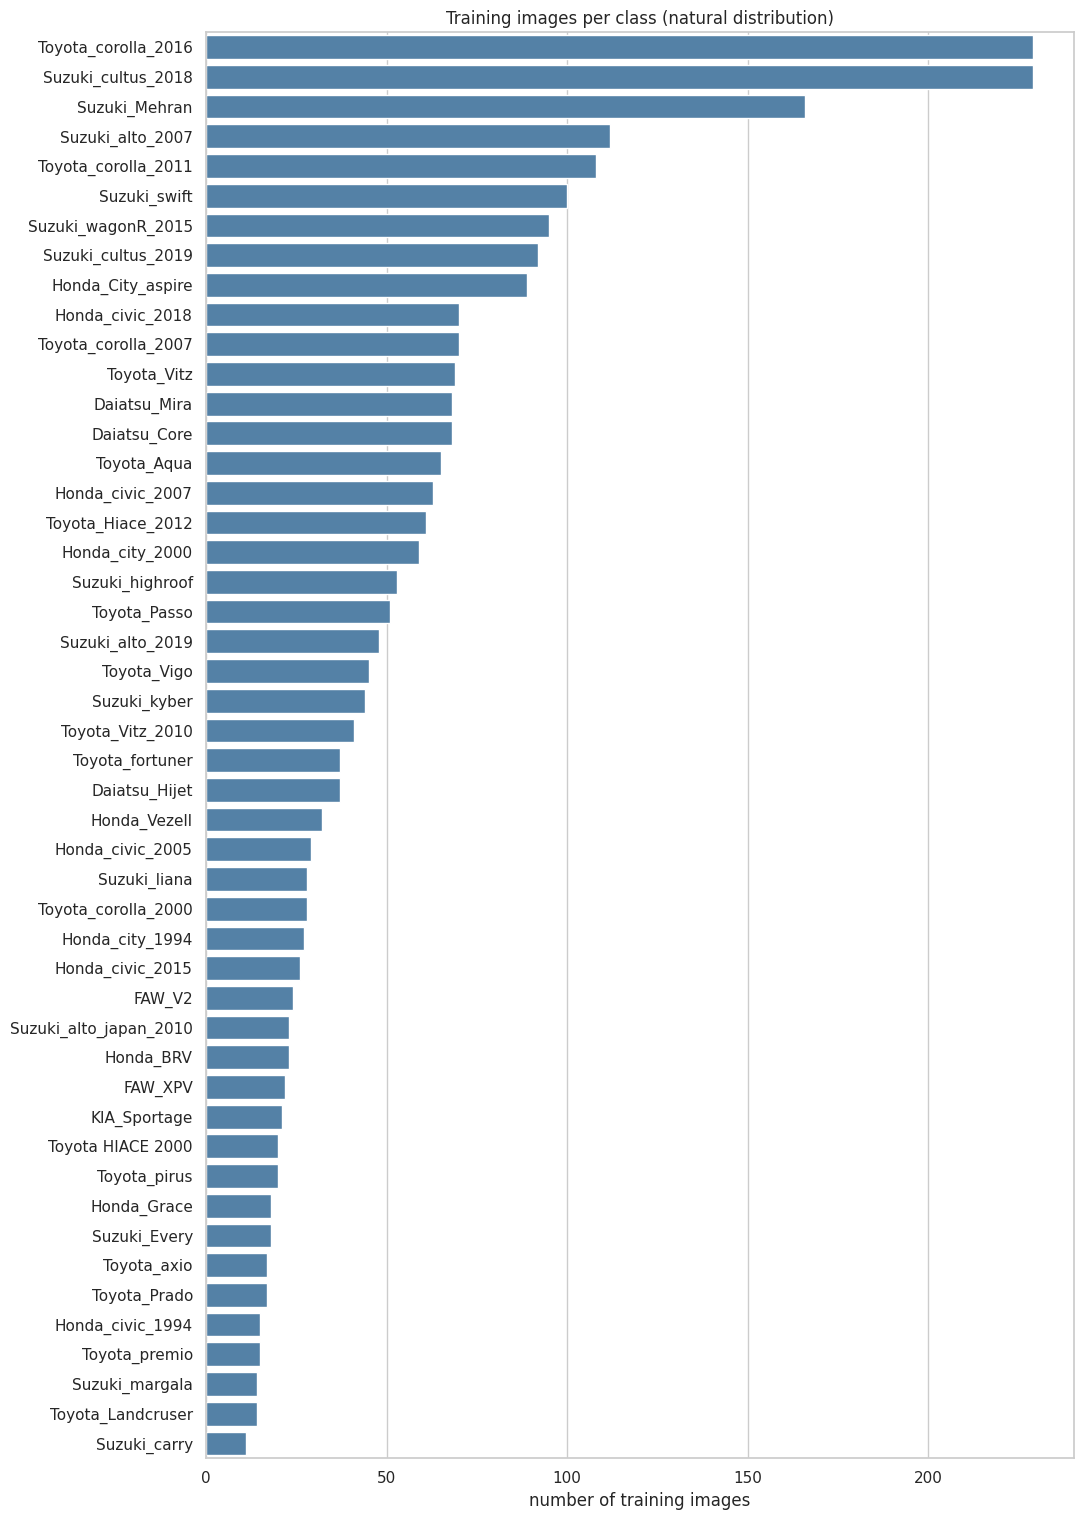

In [ ]:
# =====================================================================
# 3. DATA LOADING
# =====================================================================
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def worker_init_fn(worker_id):
    np.random.seed(SEED + worker_id); random.seed(SEED + worker_id)


def make_generator(seed=SEED):
    g = torch.Generator(); g.manual_seed(seed)
    return g


def find_split_dir(data_root):
    path = Path(data_root)
    if path.name == "Splited_dataset" and path.is_dir():
        return path
    if (path / "Splited_dataset").is_dir():
        return path / "Splited_dataset"
    for base in SEARCH_ROOTS:                      # fallback: search the input folders
        for dirpath, dirnames, _ in os.walk(base):
            if "Splited_dataset" in dirnames:
                return Path(dirpath) / "Splited_dataset"
    raise FileNotFoundError("Splited_dataset folder not found. Attach the dataset via Add Input.")


def is_valid_image(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False


def scan_split(split_dir):
    """Return (class_names, image_paths, integer_labels) for one split folder."""
    class_names = sorted(d.name for d in split_dir.iterdir() if d.is_dir() and not d.name.startswith("."))
    paths, labels = [], []
    for idx, name in enumerate(class_names):
        for f in sorted((split_dir / name).iterdir()):
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS and is_valid_image(f):
                paths.append(str(f)); labels.append(idx)
    return class_names, np.array(paths), np.array(labels)


def prepare_data():
    root = find_split_dir(DATA_ROOT)
    class_names, paths, labels = scan_split(root / "train")
    test_classes, test_paths, test_labels = scan_split(root / "test")
    assert class_names == test_classes, "train/test class folders differ"
    train_idx, val_idx = train_test_split(
        np.arange(len(paths)), test_size=VAL_FRACTION, stratify=labels, random_state=SEED)
    assert not set(paths[train_idx]) & set(paths[val_idx]), "train/val leakage"
    return dict(root=root, class_names=class_names, paths=paths, labels=labels,
                train_idx=train_idx, val_idx=val_idx, test_paths=test_paths, test_labels=test_labels)


DATA = prepare_data()
CLASS_NAMES = DATA["class_names"]
N_CLASSES = len(CLASS_NAMES)
TRAIN_COUNTS = np.bincount(DATA["labels"][DATA["train_idx"]], minlength=N_CLASSES)

counts_df = pd.DataFrame({
    "class_name": CLASS_NAMES,
    "train": TRAIN_COUNTS,
    "val": np.bincount(DATA["labels"][DATA["val_idx"]], minlength=N_CLASSES),
    "test": np.bincount(DATA["test_labels"], minlength=N_CLASSES),
}).sort_values("train", ascending=False).reset_index(drop=True)

print(f"classes: {N_CLASSES} | train: {len(DATA['train_idx'])} | val: {len(DATA['val_idx'])} | test: {len(DATA['test_paths'])}")
print(f"imbalance ratio (largest / smallest class): {TRAIN_COUNTS.max() / TRAIN_COUNTS.min():.1f}x")
display(counts_df)

fig, ax = plt.subplots(figsize=(11, max(4, 0.32 * N_CLASSES)))
sns.barplot(data=counts_df, y="class_name", x="train", color="steelblue", ax=ax)
ax.set_title("Training images per class (natural distribution)")
ax.set_xlabel("number of training images"); ax.set_ylabel("")
fig.tight_layout(); fig.savefig(WORK / "01_class_distribution.png", dpi=150); plt.show()

---
## 4. Albumentations pipelines
Three levels are defined. Only API calls that are stable across Albumentations 1.4 and 2.x are used.

| Level | Used for | Operations |
|-------|----------|-----------|
| `none` | validation, test, and the **BEFORE** experiments | resize + normalize only |
| `standard` | majority classes in the **AFTER** experiment | flip, mild affine, brightness/contrast, small hue shift |
| `strong` | **minority classes** (fewer images than the median class) | all of the above, stronger, plus blur and rare grayscale |

Minority classes are oversampled by the balancer, so each of their images is seen many times per epoch.
Strong augmentation makes each repeat look different and prevents the model from simply memorising them.
Hue shifts are kept very small so vehicle colour is not destroyed.

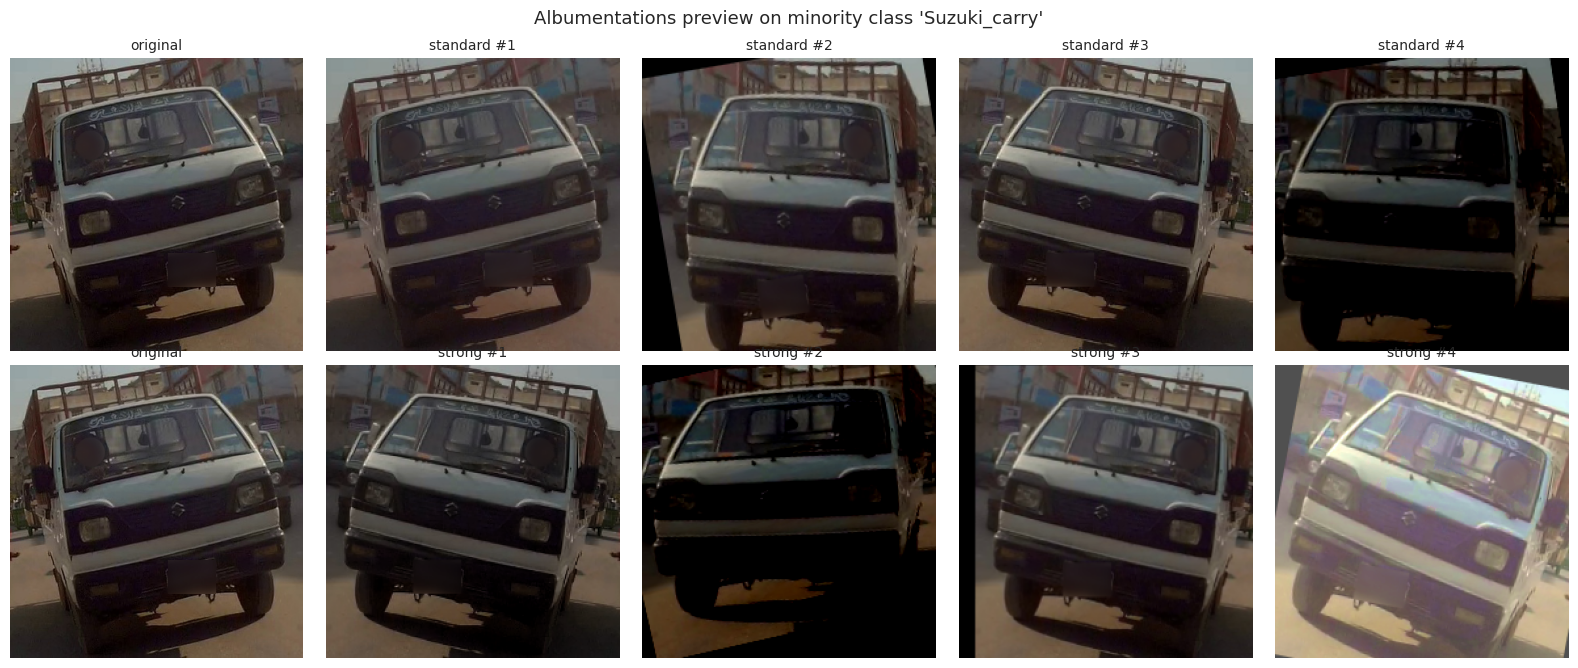

In [ ]:
# =====================================================================
# 4. ALBUMENTATIONS PIPELINES + DATASET
# =====================================================================
def build_pipeline(level):
    resize = [A.Resize(IMAGE_SIZE, IMAGE_SIZE)]
    tail = [A.Normalize(mean=MEAN, std=STD), ToTensorV2()]
    if level == "none":
        ops = []
    elif level == "standard":
        ops = [
            A.HorizontalFlip(p=0.5),
            A.Affine(scale=(0.85, 1.15), translate_percent=(-0.06, 0.06), rotate=(-10, 10), p=0.6),
            A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
            A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=15, val_shift_limit=10, p=0.3),
        ]
    elif level == "strong":
        ops = [
            A.HorizontalFlip(p=0.5),
            A.Affine(scale=(0.70, 1.25), translate_percent=(-0.10, 0.10), rotate=(-15, 15), p=0.8),
            A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.7),
            A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=25, val_shift_limit=15, p=0.5),
            A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.MotionBlur(blur_limit=5)], p=0.3),
            A.ToGray(p=0.05),
        ]
    else:
        raise ValueError(level)
    return A.Compose(resize + ops + tail)


PIPELINES = {lvl: build_pipeline(lvl) for lvl in ("none", "standard", "strong")}


def make_class_policy(augmentation):
    """Map every class index -> augmentation level."""
    if augmentation == "none":
        return {c: "none" for c in range(N_CLASSES)}
    median = np.median(TRAIN_COUNTS)
    return {c: ("strong" if TRAIN_COUNTS[c] < median else "standard") for c in range(N_CLASSES)}


class VehicleDataset(Dataset):
    """Loads an RGB image and applies the Albumentations level assigned to its class."""
    def __init__(self, paths, labels, indices, policy):
        self.paths, self.labels = paths, labels
        self.indices = np.asarray(indices)
        self.policy = policy

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        label = int(self.labels[j])
        with Image.open(self.paths[j]) as im:
            image = np.array(im.convert("RGB"))
        tensor = PIPELINES[self.policy[label]](image=image)["image"]
        return tensor, label


# ---- visual preview: one minority-class image, original vs augmented ----
smallest = int(np.argmin(TRAIN_COUNTS))
sample_path = DATA["paths"][DATA["train_idx"]][DATA["labels"][DATA["train_idx"]] == smallest][0]
original = np.array(Image.open(sample_path).convert("RGB"))
preview = {lvl: A.Compose([t for t in PIPELINES[lvl].transforms if not isinstance(t, (A.Normalize, ToTensorV2))])
           for lvl in ("standard", "strong")}

fig, axes = plt.subplots(2, 5, figsize=(16, 6.8))
for r, lvl in enumerate(("standard", "strong")):
    axes[r, 0].imshow(original); axes[r, 0].set_title("original", fontsize=10)
    for c in range(1, 5):
        axes[r, c].imshow(preview[lvl](image=original)["image"]); axes[r, c].set_title(f"{lvl} #{c}", fontsize=10)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle(f"Albumentations preview on minority class '{CLASS_NAMES[smallest]}'", fontsize=13)
fig.tight_layout(); fig.savefig(WORK / "02_augmentation_preview.png", dpi=150); plt.show()

---
## 5. Class balancing
A `WeightedRandomSampler` gives each training image the weight `1 / (images in its class)`.
Every class then has the **same probability of being drawn**, so each epoch contains about the same number of
images per class, whatever the original counts. (Weighted loss was avoided on purpose: earlier runs showed
it destabilises training on very small classes.)

The next cell **proves** the balancing by drawing one full epoch from the sampler and counting images per class.

Imbalance ratio  natural :   20.8x   |   balanced :  1.84x
Coefficient of variation natural : 0.89   |   balanced : 0.13   (0 = perfectly balanced)
Expected images per class per epoch when balanced: 55


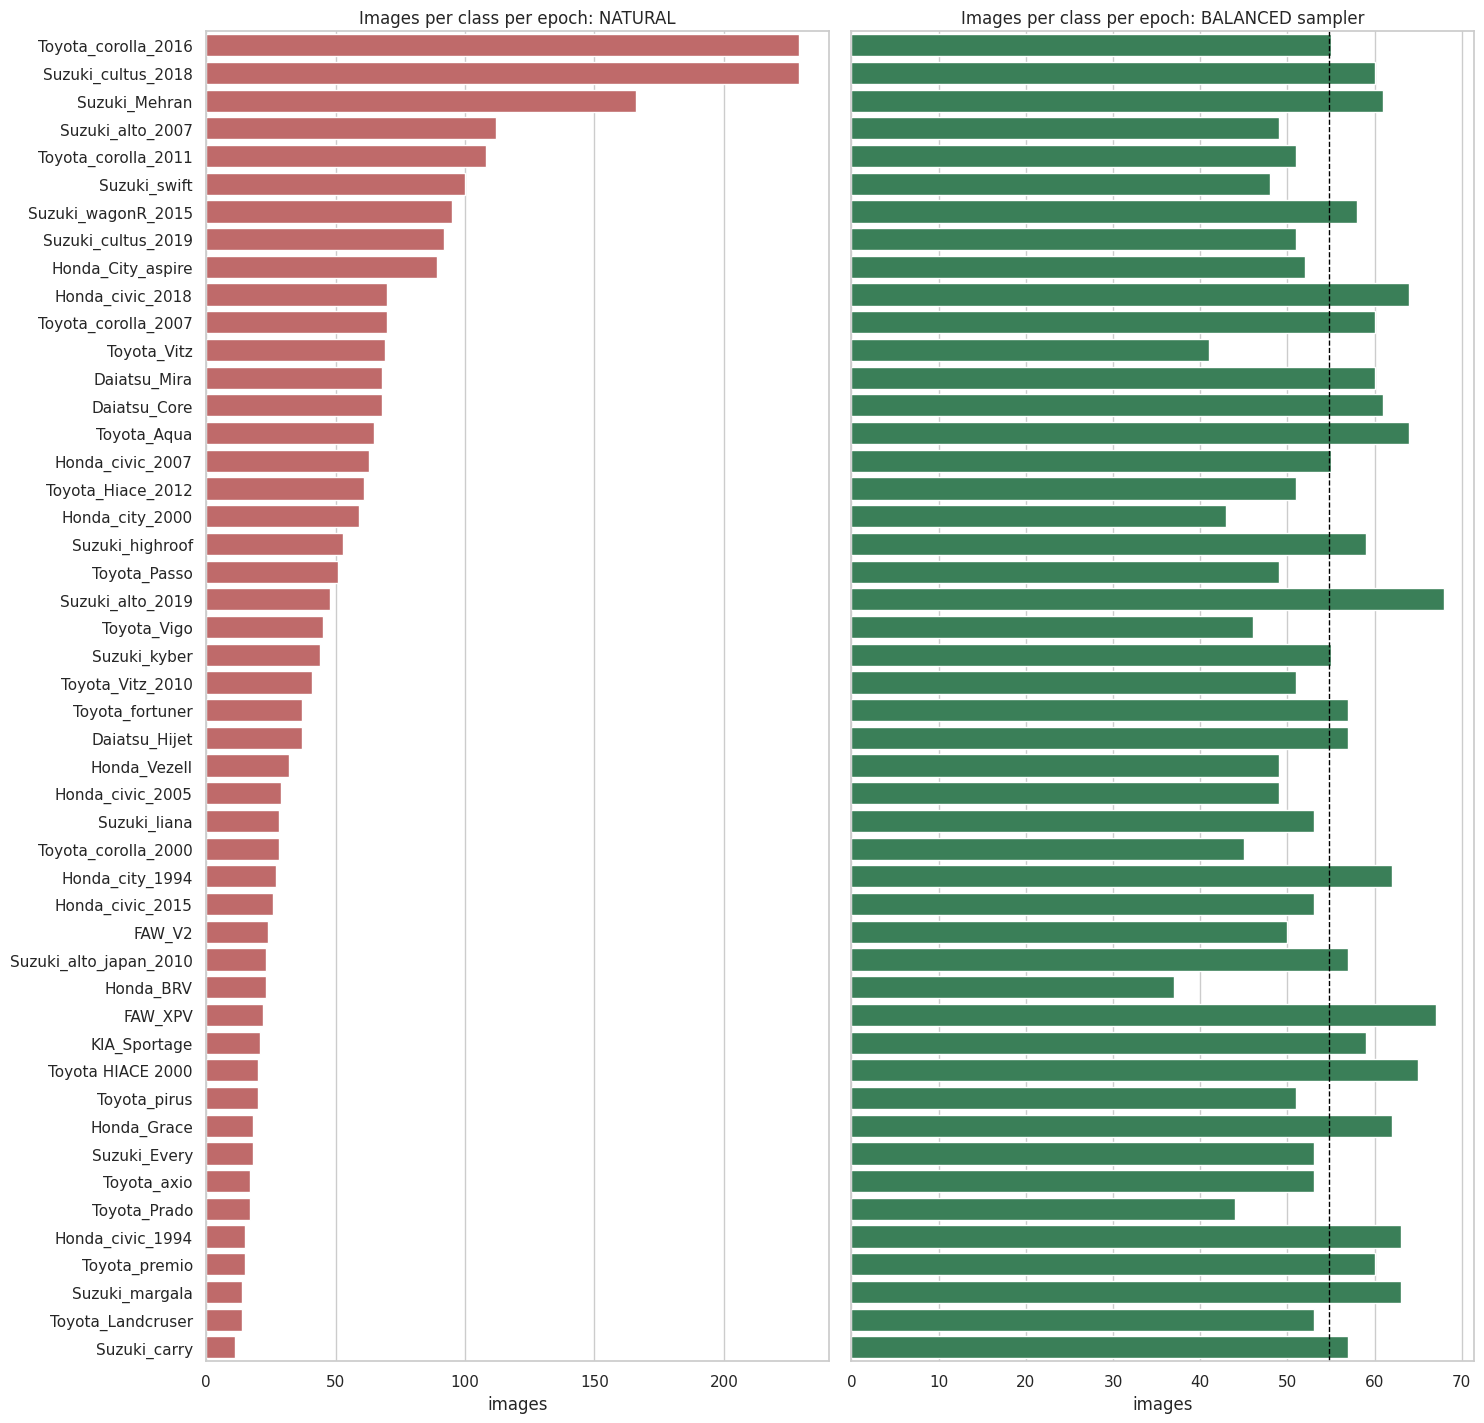

In [ ]:
# =====================================================================
# 5. CLASS BALANCING (+ verification)
# =====================================================================
TRAIN_LABELS = DATA["labels"][DATA["train_idx"]]

def make_balanced_sampler(seed=SEED):
    weights = 1.0 / TRAIN_COUNTS[TRAIN_LABELS]                  # rare class -> larger weight
    return WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double),
                                 num_samples=len(TRAIN_LABELS), replacement=True,
                                 generator=make_generator(seed))

drawn = np.fromiter(iter(make_balanced_sampler()), dtype=int)   # indices into the train subset
balanced_counts = np.bincount(TRAIN_LABELS[drawn], minlength=N_CLASSES)

check = pd.DataFrame({"class_name": CLASS_NAMES,
                      "natural_per_epoch": TRAIN_COUNTS,
                      "balanced_per_epoch": balanced_counts}).sort_values("natural_per_epoch", ascending=False)
cv = lambda x: x.std() / x.mean()
print(f"Imbalance ratio  natural : {TRAIN_COUNTS.max() / TRAIN_COUNTS.min():6.1f}x   |   balanced : {balanced_counts.max() / max(balanced_counts.min(), 1):5.2f}x")
print(f"Coefficient of variation natural : {cv(TRAIN_COUNTS):.2f}   |   balanced : {cv(balanced_counts):.2f}   (0 = perfectly balanced)")
print(f"Expected images per class per epoch when balanced: {len(TRAIN_LABELS) / N_CLASSES:.0f}")

fig, axes = plt.subplots(1, 2, figsize=(15, max(4, 0.3 * N_CLASSES)), sharey=True)
sns.barplot(data=check, y="class_name", x="natural_per_epoch", color="indianred", ax=axes[0])
axes[0].set_title("Images per class per epoch: NATURAL")
sns.barplot(data=check, y="class_name", x="balanced_per_epoch", color="seagreen", ax=axes[1])
axes[1].set_title("Images per class per epoch: BALANCED sampler")
for ax in axes:
    ax.set_xlabel("images"); ax.set_ylabel("")
axes[1].axvline(len(TRAIN_LABELS) / N_CLASSES, ls="--", c="black", lw=1)
fig.tight_layout(); fig.savefig(WORK / "03_balancing_check.png", dpi=150); plt.show()

---
## 6. Model and training engine

**Transfer-learning strategy (two stages)**

| Stage | Trainable parts | Learning rate | Purpose |
|-------|-----------------|---------------|---------|
| 1 (5 epochs) | new classifier head only; backbone frozen (BatchNorm frozen too) | 1e-3 | Align the new head with the pretrained features |
| 2 (up to 15 epochs, early stopping) | head + backbone blocks 10-18 | backbone 1e-4, head 5e-4, cosine decay | Adapt the upper ImageNet features to vehicles |

The best epoch is chosen by **validation macro-F1** (fair to small classes), never by test results.
After training, `verify_transfer` checks that the frozen blocks (0-9) are still **bit-identical** to the ImageNet
weights, which proves the pretrained backbone was really used.

In [ ]:
# =====================================================================
# 6. MODEL + TRAINING ENGINE
# =====================================================================
def build_model(n_classes):
    """MobileNetV2 with ImageNet weights and a new classifier head (transfer learning)."""
    model = models.mobilenet_v2(weights=None)
    model.load_state_dict(PRETRAINED_STATE, strict=True)                 # <- the pretrained weights
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(in_features, n_classes))
    # Hard check: backbone really holds the pretrained tensors
    assert torch.equal(model.features[0][0].weight.cpu(), PRETRAINED_STATE["features.0.0.weight"].cpu()), \
        "pretrained weights were not applied"
    return model


def verify_transfer(model):
    """After training: frozen blocks must equal ImageNet weights; fine-tuned blocks should have moved."""
    sd = model.state_dict()
    frozen_prefix = tuple(f"features.{i}." for i in range(UNFREEZE_FROM))
    frozen_same = all(torch.equal(sd[k].cpu(), PRETRAINED_STATE[k].cpu())
                      for k in PRETRAINED_STATE if k.startswith(frozen_prefix))
    tuned = [k for k in PRETRAINED_STATE if k.startswith("features.") and not k.startswith(frozen_prefix)
             and PRETRAINED_STATE[k].dtype.is_floating_point]
    moved = float(np.mean([not torch.equal(sd[k].cpu(), PRETRAINED_STATE[k].cpu()) for k in tuned]))
    return frozen_same, moved


def stage_modules(model, stage):
    if stage == 1:
        return [model.classifier]
    return [model.classifier] + list(model.features[UNFREEZE_FROM:])


def set_trainable(model, modules):
    for p in model.parameters():
        p.requires_grad = False
    for m in modules:
        for p in m.parameters():
            p.requires_grad = True


def set_train_mode(model, modules):
    model.eval()                       # keeps BatchNorm of frozen layers fixed
    for m in modules:
        m.train()


def compute_metrics(y_true, y_pred, prefix):
    labels = np.arange(N_CLASSES)
    return {
        f"{prefix}_acc": float(accuracy_score(y_true, y_pred)),
        f"{prefix}_balanced_acc": float(balanced_accuracy_score(y_true, y_pred)),
        f"{prefix}_macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        f"{prefix}_weighted_f1": float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
        f"{prefix}_macro_precision": float(precision_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        f"{prefix}_macro_recall": float(recall_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
    }


def train_one_epoch(model, loader, criterion, optimizer, scaler, modules):
    set_train_mode(model, modules)
    total, seen = 0.0, 0
    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            loss = criterion(model(images), targets)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        total += loss.item() * targets.size(0); seen += targets.size(0)
    return total / seen


@torch.no_grad()
def predict(model, loader, criterion):
    model.eval()
    total, seen, preds, truths = 0.0, 0, [], []
    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            out = model(images)
            loss = criterion(out, targets)
        total += loss.item() * targets.size(0); seen += targets.size(0)
        preds.append(out.argmax(1).cpu().numpy()); truths.append(targets.cpu().numpy())
    return total / seen, np.concatenate(preds), np.concatenate(truths)


def fit_stage(model, stage, epochs, optimizer, scheduler, modules, loaders, criterion, state, patience=None):
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    stale = 0
    for _ in range(epochs):
        lr = optimizer.param_groups[0]["lr"]
        train_loss = train_one_epoch(model, loaders["train"], criterion, optimizer, scaler, modules)
        val_loss, vp, vt = predict(model, loaders["val"], criterion)
        vm = compute_metrics(vt, vp, "val")
        if scheduler is not None:
            scheduler.step()
        state["step"] += 1
        state["history"].append(dict(epoch=state["step"], stage=stage, lr=lr,
                                     train_loss=train_loss, val_loss=val_loss, **vm))
        improved = vm["val_macro_f1"] > state["best_f1"]
        if improved:
            state["best_f1"] = vm["val_macro_f1"]
            torch.save(model.state_dict(), state["checkpoint"])
            stale = 0
        else:
            stale += 1
        print(f"  [stage {stage}] epoch {state['step']:02d} | lr {lr:.1e} | train {train_loss:.4f} | "
              f"val {val_loss:.4f} | val acc {vm['val_acc']:.4f} | val macro-F1 {vm['val_macro_f1']:.4f}"
              f"{'  *best*' if improved else ''}")
        if patience is not None and stale >= patience:
            print(f"  early stopping (no improvement for {patience} epochs)")
            break

---
## 7. Run experiments
Each experiment trains from the **same seed and the same pretrained weights**, so the only differences are
the balancing and augmentation settings in the table at the top. Per-experiment curves, confusion matrices,
classification reports and per-class CSVs are written to `/kaggle/working`.

This cell trains three models (A, B, C) and takes the longest; on a Kaggle T4 expect roughly 10-30 minutes each,
depending on dataset size.


EXPERIMENT A_no_aug_imbalanced  |  balance=False  augmentation=none
  stage 1: training head only (61,488 trainable params)
  [stage 1] epoch 01 | lr 1.0e-03 | train 3.3256 | val 2.8390 | val acc 0.3806 | val macro-F1 0.1474  *best*
  [stage 1] epoch 02 | lr 1.0e-03 | train 2.6008 | val 2.3634 | val acc 0.5634 | val macro-F1 0.3477  *best*
  [stage 1] epoch 03 | lr 1.0e-03 | train 2.2059 | val 2.1784 | val acc 0.5656 | val macro-F1 0.4048  *best*
  [stage 1] epoch 04 | lr 1.0e-03 | train 1.9866 | val 2.0183 | val acc 0.6194 | val macro-F1 0.4838  *best*
  [stage 1] epoch 05 | lr 1.0e-03 | train 1.8122 | val 1.9087 | val acc 0.6495 | val macro-F1 0.4991  *best*
  stage 2: fine-tuning head + backbone blocks 10-18 (2,100,272 trainable params)
  [stage 2] epoch 06 | lr 1.0e-04 | train 1.5614 | val 1.3203 | val acc 0.8409 | val macro-F1 0.7700  *best*
  [stage 2] epoch 07 | lr 9.9e-05 | train 1.0576 | val 1.2176 | val acc 0.8774 | val macro-F1 0.8232  *best*
  [stage 2] epoch 08 | lr 9.6e-

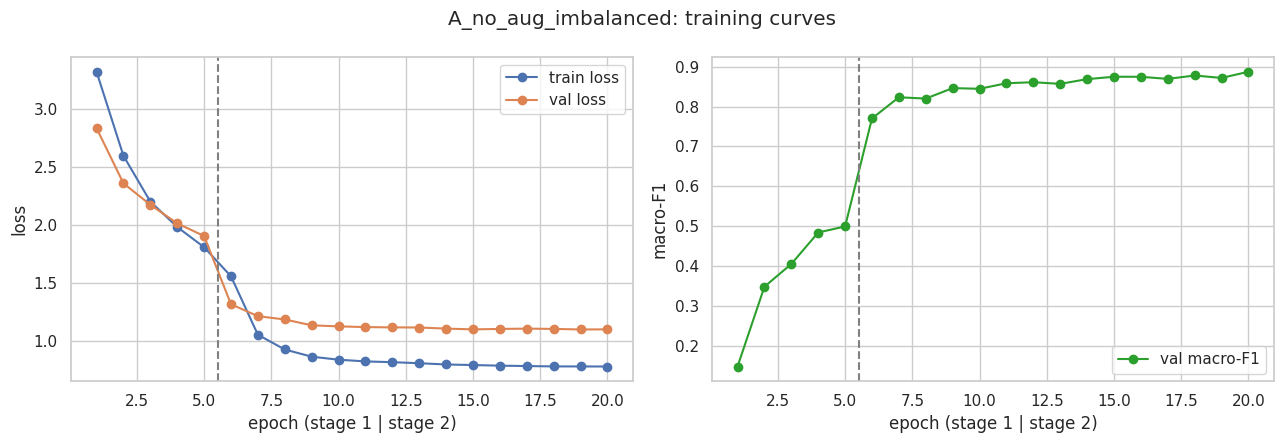

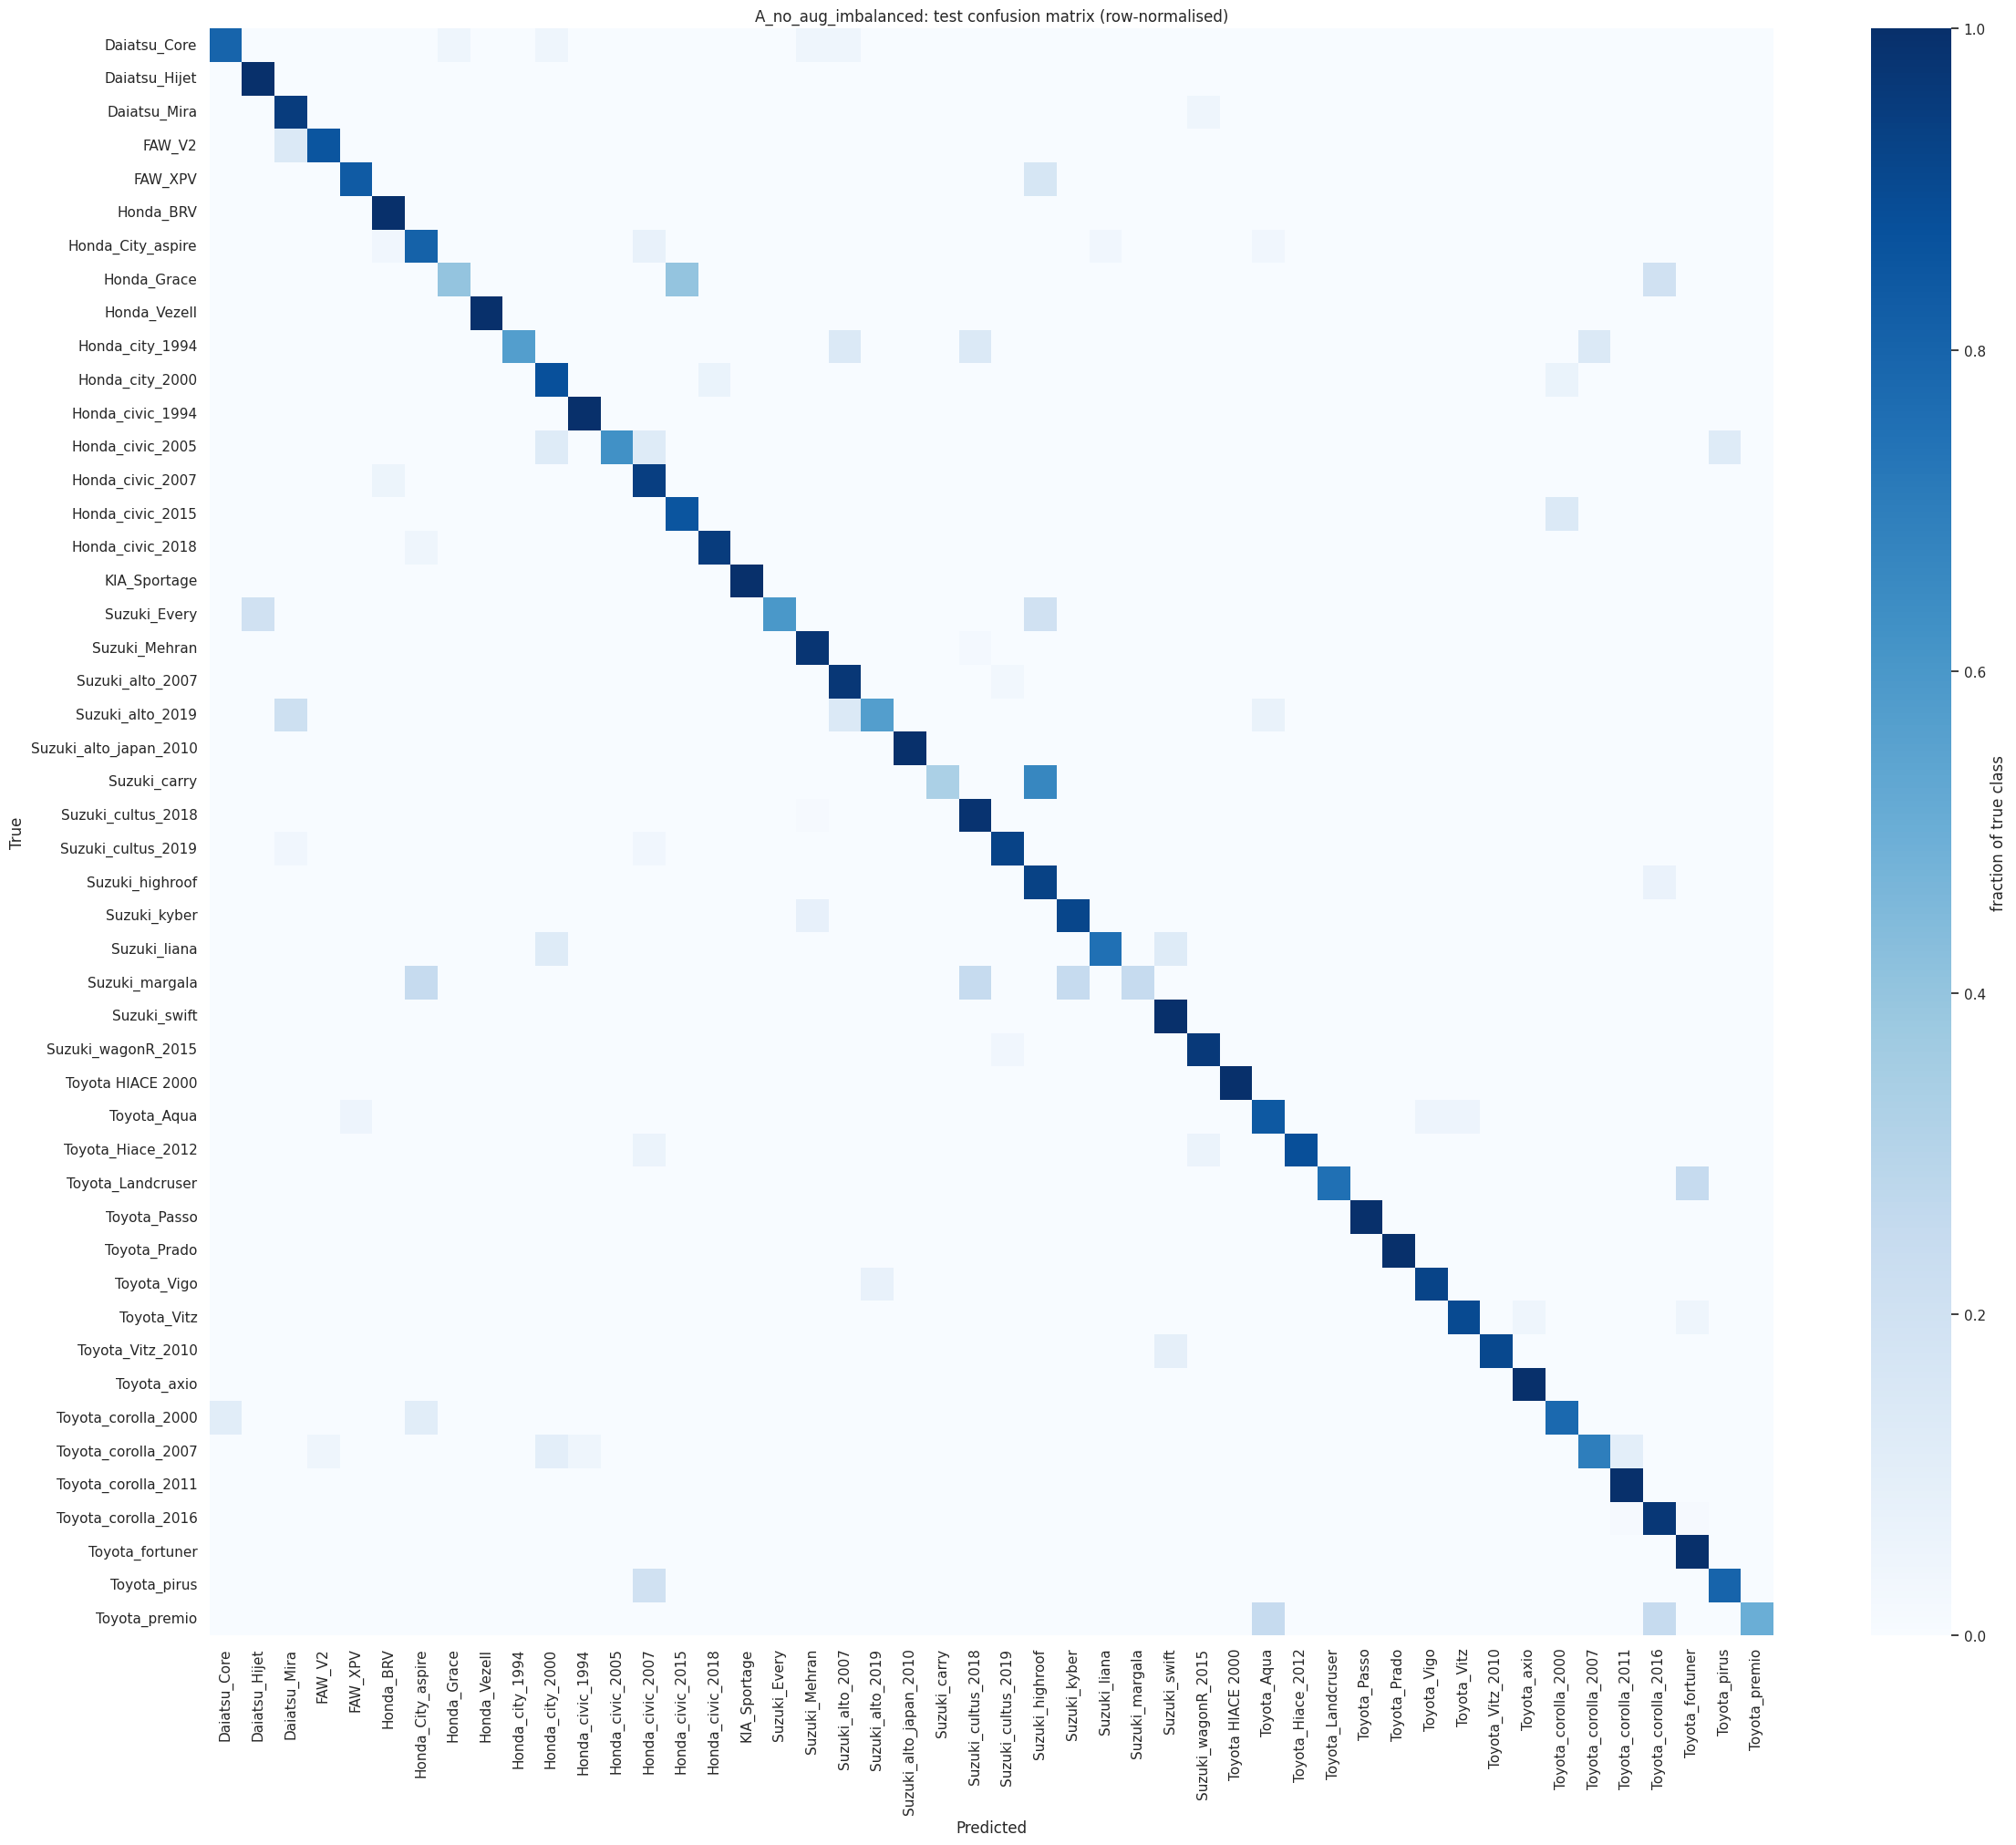


EXPERIMENT B_no_aug_balanced  |  balance=True  augmentation=none
  stage 1: training head only (61,488 trainable params)
  [stage 1] epoch 01 | lr 1.0e-03 | train 3.4200 | val 3.0469 | val acc 0.3290 | val macro-F1 0.2883  *best*
  [stage 1] epoch 02 | lr 1.0e-03 | train 2.5851 | val 2.5615 | val acc 0.5011 | val macro-F1 0.4155  *best*
  [stage 1] epoch 03 | lr 1.0e-03 | train 2.1591 | val 2.3323 | val acc 0.5570 | val macro-F1 0.5384  *best*
  [stage 1] epoch 04 | lr 1.0e-03 | train 1.9489 | val 2.1049 | val acc 0.6452 | val macro-F1 0.5894  *best*
  [stage 1] epoch 05 | lr 1.0e-03 | train 1.7221 | val 2.0347 | val acc 0.6323 | val macro-F1 0.5870
  stage 2: fine-tuning head + backbone blocks 10-18 (2,100,272 trainable params)
  [stage 2] epoch 06 | lr 1.0e-04 | train 1.4450 | val 1.4443 | val acc 0.7892 | val macro-F1 0.7514  *best*
  [stage 2] epoch 07 | lr 9.9e-05 | train 1.0447 | val 1.2572 | val acc 0.8667 | val macro-F1 0.8360  *best*
  [stage 2] epoch 08 | lr 9.6e-05 | train 

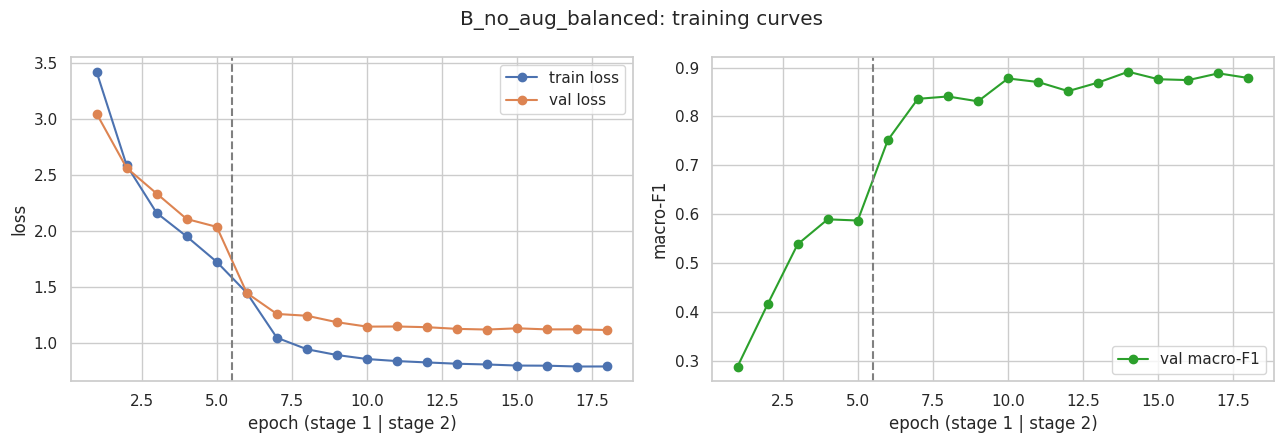

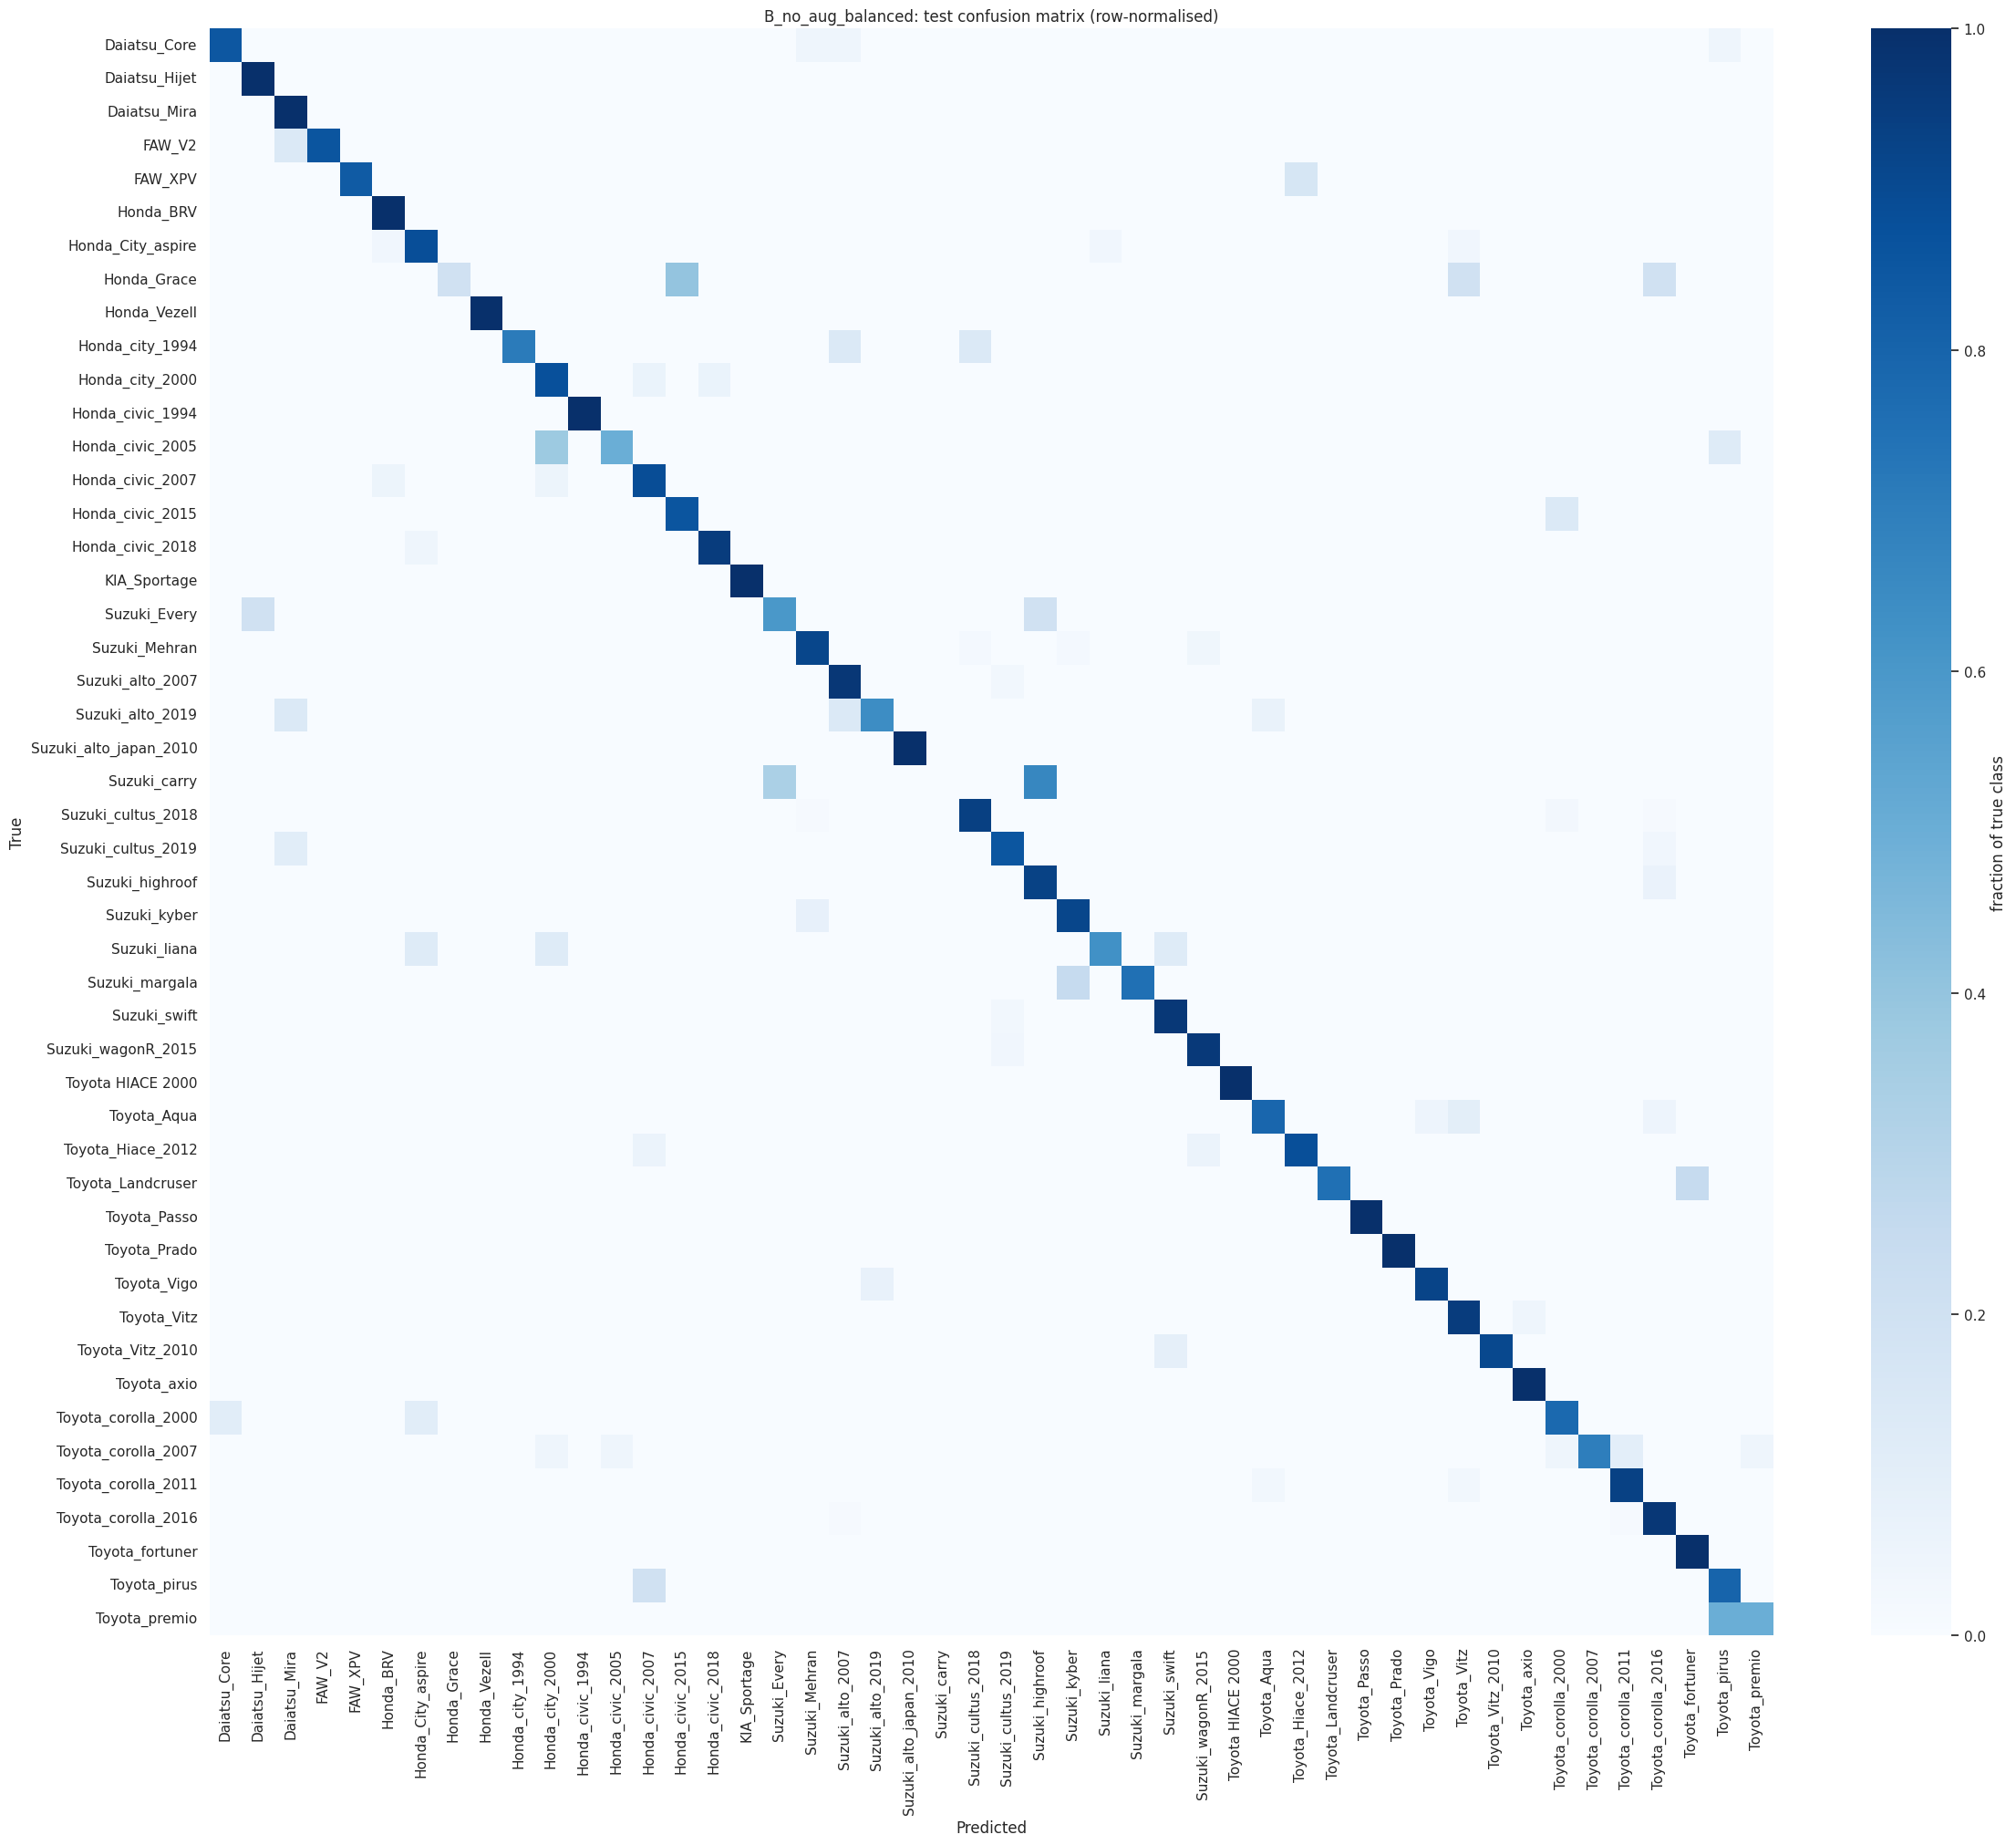


EXPERIMENT C_aug_balanced  |  balance=True  augmentation=albumentations
  augmentation levels per class: {'standard': 24, 'strong': 24}
  stage 1: training head only (61,488 trainable params)
  [stage 1] epoch 01 | lr 1.0e-03 | train 3.5222 | val 3.0516 | val acc 0.3226 | val macro-F1 0.2277  *best*
  [stage 1] epoch 02 | lr 1.0e-03 | train 2.8000 | val 2.6063 | val acc 0.4946 | val macro-F1 0.4020  *best*
  [stage 1] epoch 03 | lr 1.0e-03 | train 2.4539 | val 2.3869 | val acc 0.5226 | val macro-F1 0.4461  *best*
  [stage 1] epoch 04 | lr 1.0e-03 | train 2.2516 | val 2.2023 | val acc 0.5914 | val macro-F1 0.4839  *best*
  [stage 1] epoch 05 | lr 1.0e-03 | train 2.0580 | val 2.1062 | val acc 0.5892 | val macro-F1 0.5285  *best*
  stage 2: fine-tuning head + backbone blocks 10-18 (2,100,272 trainable params)
  [stage 2] epoch 06 | lr 1.0e-04 | train 1.8330 | val 1.4843 | val acc 0.7763 | val macro-F1 0.7314  *best*
  [stage 2] epoch 07 | lr 9.9e-05 | train 1.3414 | val 1.2985 | val acc 

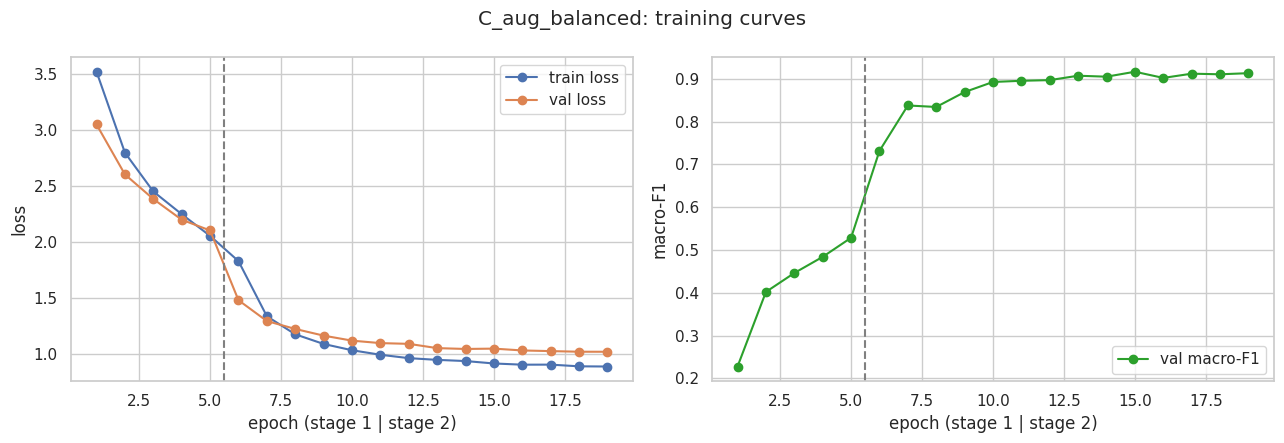

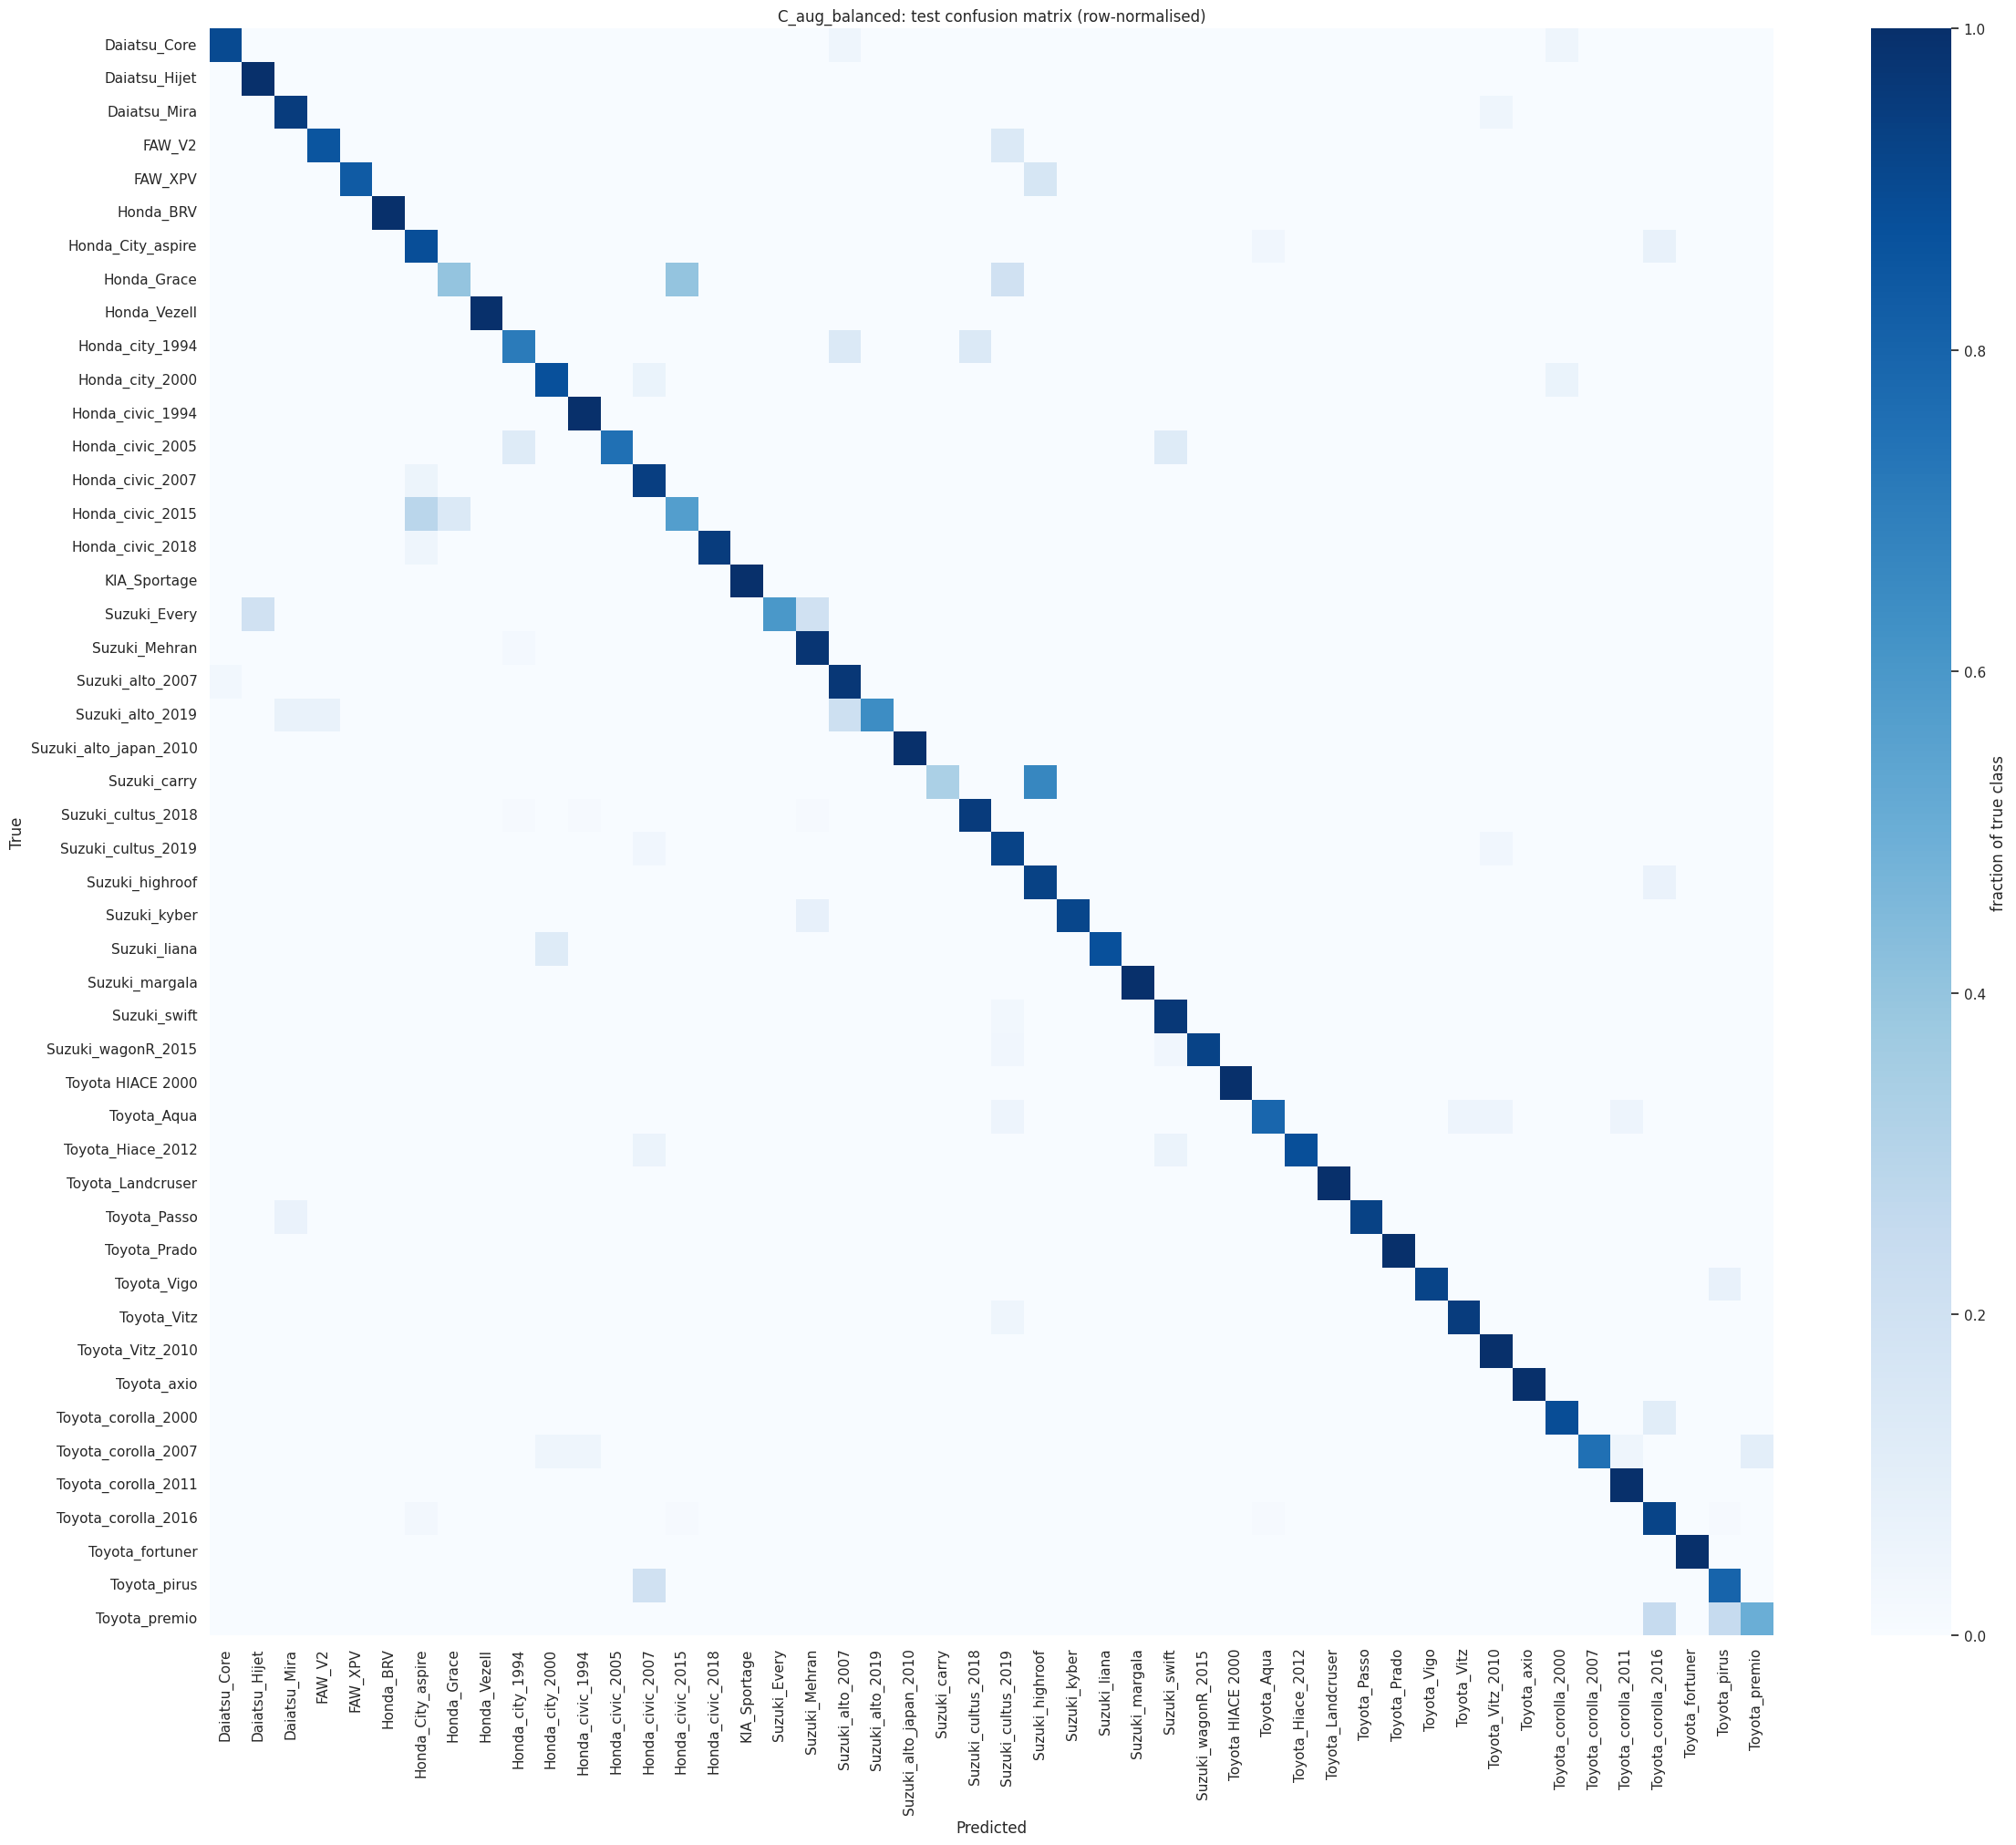

In [ ]:
# =====================================================================
# 7. EXPERIMENT RUNNER
# =====================================================================
EXPERIMENTS = {
    "A_no_aug_imbalanced": {"balance": False, "augmentation": "none"},
    "B_no_aug_balanced":   {"balance": True,  "augmentation": "none"},            # BEFORE
    "C_aug_balanced":      {"balance": True,  "augmentation": "albumentations"},  # AFTER
}
BEFORE, AFTER = "B_no_aug_balanced", "C_aug_balanced"


def make_loader(ds, shuffle=False, sampler=None):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, sampler=sampler,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                      worker_init_fn=worker_init_fn, generator=make_generator(),
                      persistent_workers=NUM_WORKERS > 0)


def build_loaders(config):
    train_policy = make_class_policy(config["augmentation"])
    eval_policy = make_class_policy("none")
    train_ds = VehicleDataset(DATA["paths"], DATA["labels"], DATA["train_idx"], train_policy)
    val_ds = VehicleDataset(DATA["paths"], DATA["labels"], DATA["val_idx"], eval_policy)
    test_ds = VehicleDataset(DATA["test_paths"], DATA["test_labels"], np.arange(len(DATA["test_paths"])), eval_policy)
    sampler = make_balanced_sampler() if config["balance"] else None
    return {"train": make_loader(train_ds, shuffle=sampler is None, sampler=sampler),
            "val": make_loader(val_ds), "test": make_loader(test_ds)}, train_policy


def save_figure(fig, name):
    fig.tight_layout(); fig.savefig(WORK / name, dpi=150, bbox_inches="tight"); plt.show()


def plot_curves(name, history):
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(h.epoch, h.train_loss, "o-", label="train loss"); axes[0].plot(h.epoch, h.val_loss, "o-", label="val loss")
    axes[0].set_ylabel("loss")
    axes[1].plot(h.epoch, h.val_macro_f1, "o-", color="tab:green", label="val macro-F1"); axes[1].set_ylabel("macro-F1")
    for ax in axes:
        ax.axvline(STAGE1_EPOCHS + 0.5, ls="--", c="gray"); ax.set_xlabel("epoch (stage 1 | stage 2)"); ax.legend()
    fig.suptitle(f"{name}: training curves")
    save_figure(fig, f"{name}_curves.png")


def plot_confusion(name, matrix):
    rows = matrix.sum(1, keepdims=True)
    norm = np.divide(matrix, rows, out=np.zeros(matrix.shape, float), where=rows > 0)
    side = max(8, 0.5 * N_CLASSES)
    fig, ax = plt.subplots(figsize=(side, side * 0.85))
    sns.heatmap(norm, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap="Blues", vmin=0, vmax=1,
                annot=N_CLASSES <= 15, fmt=".2f", ax=ax, cbar_kws={"label": "fraction of true class"})
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{name}: test confusion matrix (row-normalised)")
    plt.setp(ax.get_xticklabels(), rotation=90)
    save_figure(fig, f"{name}_confusion_matrix.png")


def run_experiment(name, config):
    print(f"\n{'=' * 78}\nEXPERIMENT {name}  |  balance={config['balance']}  augmentation={config['augmentation']}\n{'=' * 78}")
    seed_everything(SEED)
    loaders, policy = build_loaders(config)
    if config["augmentation"] != "none":
        print("  augmentation levels per class:", pd.Series(policy).value_counts().to_dict())

    model = build_model(N_CLASSES).to(DEVICE)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    state = dict(step=0, best_f1=-1.0, history=[], checkpoint=WORK / f"best_{name}.pt")

    # ---- stage 1: head only ----
    mods1 = stage_modules(model, 1); set_trainable(model, mods1)
    n1 = sum(p.numel() for p in model.parameters() if p.requires_grad)
    opt1 = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR_STAGE1, weight_decay=WEIGHT_DECAY)
    print(f"  stage 1: training head only ({n1:,} trainable params)")
    t0 = time.time()
    fit_stage(model, 1, STAGE1_EPOCHS, opt1, None, mods1, loaders, criterion, state)

    # ---- stage 2: head + upper backbone ----
    mods2 = stage_modules(model, 2); set_trainable(model, mods2)
    n2 = sum(p.numel() for p in model.parameters() if p.requires_grad)
    backbone_params = [p for m in mods2[1:] for p in m.parameters()]
    opt2 = torch.optim.AdamW([{"params": backbone_params, "lr": LR_BACKBONE},
                              {"params": list(model.classifier.parameters()), "lr": LR_HEAD}],
                             weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=STAGE2_EPOCHS)
    print(f"  stage 2: fine-tuning head + backbone blocks {UNFREEZE_FROM}-18 ({n2:,} trainable params)")
    fit_stage(model, 2, STAGE2_EPOCHS, opt2, sched, mods2, loaders, criterion, state, PATIENCE)
    minutes = (time.time() - t0) / 60

    # ---- evaluate best checkpoint on the untouched test set ----
    model.load_state_dict(torch.load(state["checkpoint"], map_location=DEVICE))
    frozen_same, moved = verify_transfer(model)
    print(f"  transfer check: frozen blocks 0-{UNFREEZE_FROM - 1} identical to ImageNet = {frozen_same} | "
          f"fine-tuned tensors changed = {moved:.0%}")
    assert frozen_same, "frozen backbone changed: transfer learning is broken"
    _, y_pred, y_true = predict(model, loaders["test"], criterion)
    metrics = compute_metrics(y_true, y_pred, "test")
    print(f"  >>> TEST  acc {metrics['test_acc']:.4f} | balanced acc {metrics['test_balanced_acc']:.4f} | "
          f"macro-F1 {metrics['test_macro_f1']:.4f}   ({minutes:.1f} min)")

    labels = np.arange(N_CLASSES)
    matrix = confusion_matrix(y_true, y_pred, labels=labels)
    plot_curves(name, state["history"]); plot_confusion(name, matrix)
    prec, rec, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    per_class = pd.DataFrame(dict(class_name=CLASS_NAMES, train_count=TRAIN_COUNTS, test_support=sup,
                                  precision=prec, recall=rec, f1=f1))
    per_class.to_csv(WORK / f"{name}_per_class.csv", index=False)
    pd.DataFrame(state["history"]).to_csv(WORK / f"{name}_history.csv", index=False)
    (WORK / f"{name}_classification_report.txt").write_text(classification_report(
        y_true, y_pred, labels=labels, target_names=CLASS_NAMES, zero_division=0, digits=4))
    (WORK / f"{name}_test_metrics.json").write_text(json.dumps(
        {**metrics, "best_val_macro_f1": state["best_f1"], "config": config,
         "pretrained_source": PRETRAINED_SOURCE, "frozen_blocks_identical": frozen_same}, indent=2))

    del model; torch.cuda.empty_cache()
    return dict(metrics=metrics, y_true=y_true, y_pred=y_pred, matrix=matrix, per_class=per_class,
                history=state["history"], best_val_f1=state["best_f1"])


RESULTS = {}
for exp_name, exp_cfg in EXPERIMENTS.items():
    RESULTS[exp_name] = run_experiment(exp_name, exp_cfg)

---
## 8. Results comparison
All numbers below are measured on the **untouched test set** using the checkpoint with the best validation macro-F1.

* **Accuracy** is the share of correctly classified images.
* **Balanced accuracy / macro-F1 / macro-recall** weight every class equally, so they reveal whether small classes are being sacrificed.
* **test_errors** is the raw count of misclassified test images, the quantity this study is trying to reduce.

,experiment,balance,augmentation,test_images,test_errors,test_acc,test_balanced_acc,test_macro_f1,test_weighted_f1,test_macro_precision,test_macro_recall,best_val_macro_f1
0,A_no_aug_imbalanced,False,none,751,72,0.9041,0.8459,0.8561,0.9001,0.9015,0.8459,0.8873
1,B_no_aug_balanced,True,none,751,80,0.8935,0.8411,0.8439,0.8895,0.8711,0.8411,0.8914
2,C_aug_balanced,True,albumentations,751,67,0.9108,0.8749,0.8792,0.9100,0.9021,0.8749,0.9163


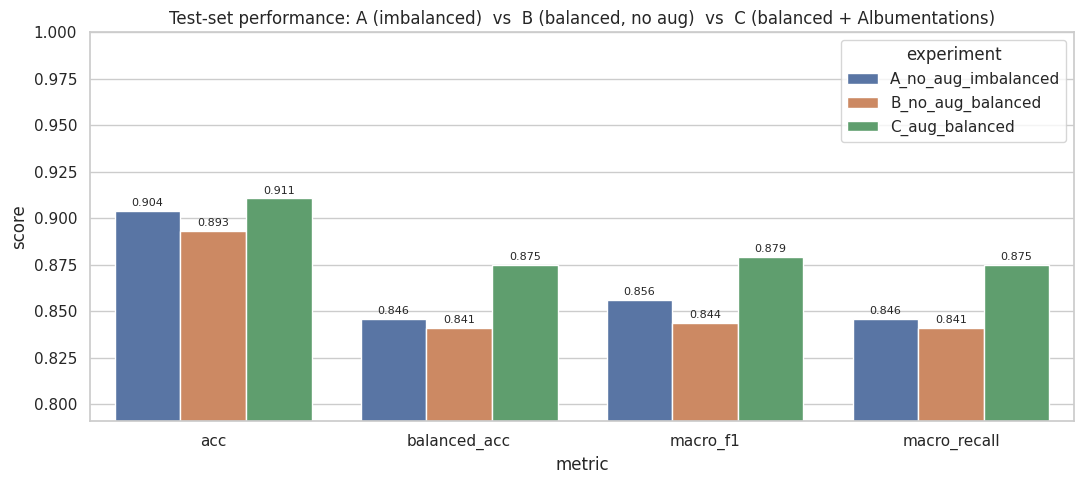

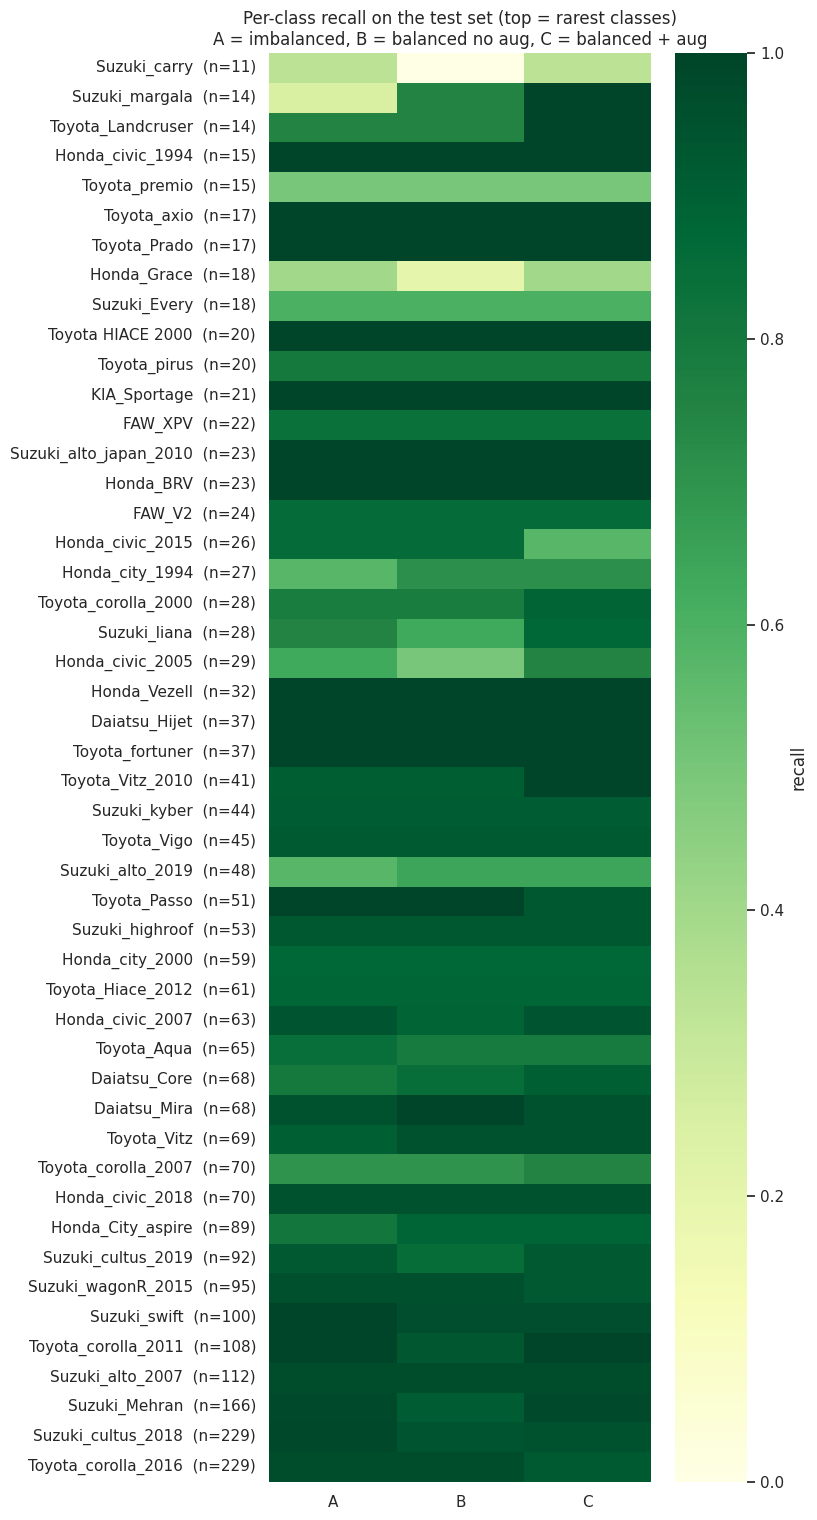

In [ ]:
# =====================================================================
# 8. RESULTS COMPARISON
# =====================================================================
rows = []
for name, r in RESULTS.items():
    yt, yp = r["y_true"], r["y_pred"]
    rows.append({"experiment": name,
                 "balance": EXPERIMENTS[name]["balance"],
                 "augmentation": EXPERIMENTS[name]["augmentation"],
                 "test_images": len(yt),
                 "test_errors": int((yt != yp).sum()),
                 **r["metrics"],
                 "best_val_macro_f1": r["best_val_f1"]})
comparison = pd.DataFrame(rows)
comparison.to_csv(WORK / "04_experiment_comparison.csv", index=False)
display(comparison.round(4))

# ---- grouped bar chart of the headline metrics ----
metric_cols = ["test_acc", "test_balanced_acc", "test_macro_f1", "test_macro_recall"]
long = comparison.melt(id_vars="experiment", value_vars=metric_cols, var_name="metric", value_name="score")
long["metric"] = long["metric"].str.replace("test_", "", regex=False)
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=long, x="metric", y="score", hue="experiment", ax=ax)
low = max(0.0, long["score"].min() - 0.05)
ax.set_ylim(low, 1.0)
ax.set_title("Test-set performance: A (imbalanced)  vs  B (balanced, no aug)  vs  C (balanced + Albumentations)")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
fig.tight_layout(); fig.savefig(WORK / "04_metric_comparison.png", dpi=150); plt.show()

# ---- per-class recall heatmap (rows sorted from rarest to most common class) ----
recall_df = pd.DataFrame({n: r["per_class"].set_index("class_name")["recall"] for n, r in RESULTS.items()})
order = pd.Series(TRAIN_COUNTS, index=CLASS_NAMES).sort_values().index
recall_df = recall_df.loc[order]
labels_with_counts = [f"{c}  (n={TRAIN_COUNTS[CLASS_NAMES.index(c)]})" for c in recall_df.index]
fig, ax = plt.subplots(figsize=(8, max(4, 0.32 * N_CLASSES)))
sns.heatmap(recall_df.values, annot=N_CLASSES <= 30, fmt=".2f", cmap="YlGn", vmin=0, vmax=1,
            xticklabels=[c.split("_")[0] for c in recall_df.columns],
            yticklabels=labels_with_counts, ax=ax, cbar_kws={"label": "recall"})
ax.set_title("Per-class recall on the test set (top = rarest classes)\nA = imbalanced, B = balanced no aug, C = balanced + aug")
fig.tight_layout(); fig.savefig(WORK / "05_per_class_recall_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

---
## 9. Misclassification analysis: before vs after augmentation
This is the core question: **did Albumentations augmentation fix misclassifications?**

Because experiments B and C use the same test images in the same order, every image can be compared directly:

| Group | Meaning |
|-------|---------|
| **Fixed** | wrong in B (before), correct in C (after) |
| **Broken** | correct in B, wrong in C (new mistakes caused by augmentation) |
| **Still wrong** | wrong in both |
| **Still correct** | correct in both |

An exact **McNemar test** (binomial test on the *fixed* vs *broken* counts) tells us whether the net change is
larger than random chance.

,group,images,share_of_test_set
0,Errors BEFORE (B),80,0.1065
1,Errors AFTER (C),67,0.0892
2,Fixed by augmentation,26,0.0346
3,Newly broken,13,0.0173
4,Still wrong,54,0.0719
5,Still correct,658,0.8762
6,Net errors removed,13,0.0173


Error rate  BEFORE: 0.1065   AFTER: 0.0892
McNemar exact test  (fixed=26, broken=13)  p-value = 0.0533  -> not statistically significant at 5 %


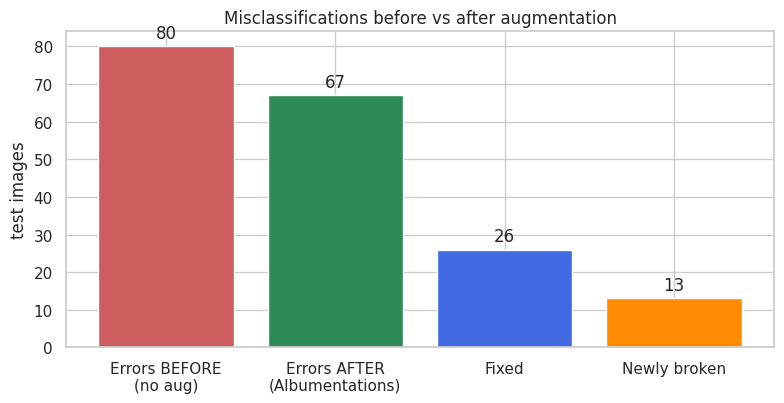

In [ ]:
# =====================================================================
# 9.1 IMAGE-LEVEL BEFORE / AFTER COMPARISON + McNEMAR TEST
# =====================================================================
yt = RESULTS[BEFORE]["y_true"]
pb = RESULTS[BEFORE]["y_pred"]
pa = RESULTS[AFTER]["y_pred"]
assert np.array_equal(yt, RESULTS[AFTER]["y_true"]) and len(yt) == len(DATA["test_paths"]), "test order mismatch"

wrong_b, wrong_a = pb != yt, pa != yt
fixed, broken = wrong_b & ~wrong_a, ~wrong_b & wrong_a
still_wrong, still_ok = wrong_b & wrong_a, ~wrong_b & ~wrong_a

n_fixed, n_broken = int(fixed.sum()), int(broken.sum())
p_value = binomtest(n_fixed, n_fixed + n_broken, 0.5).pvalue if (n_fixed + n_broken) > 0 else 1.0

summary = pd.DataFrame({
    "group": ["Errors BEFORE (B)", "Errors AFTER (C)", "Fixed by augmentation", "Newly broken",
              "Still wrong", "Still correct", "Net errors removed"],
    "images": [int(wrong_b.sum()), int(wrong_a.sum()), n_fixed, n_broken,
               int(still_wrong.sum()), int(still_ok.sum()), int(wrong_b.sum() - wrong_a.sum())],
})
summary["share_of_test_set"] = (summary["images"] / len(yt)).round(4)
display(summary)
print(f"Error rate  BEFORE: {wrong_b.mean():.4f}   AFTER: {wrong_a.mean():.4f}")
print(f"McNemar exact test  (fixed={n_fixed}, broken={n_broken})  p-value = {p_value:.4f}  "
      f"-> {'statistically significant (p < 0.05)' if p_value < 0.05 else 'not statistically significant at 5 %'}")

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(["Errors BEFORE\n(no aug)", "Errors AFTER\n(Albumentations)", "Fixed", "Newly broken"],
              [wrong_b.sum(), wrong_a.sum(), n_fixed, n_broken],
              color=["indianred", "seagreen", "royalblue", "darkorange"])
ax.bar_label(bars, padding=3)
ax.set_ylabel("test images"); ax.set_title("Misclassifications before vs after augmentation")
fig.tight_layout(); fig.savefig(WORK / "06_errors_before_after.png", dpi=150); plt.show()

,class_name,train_count,group,test_support,errors_before,errors_after,recall_before,recall_after,errors_removed,recall_change
0,Suzuki_carry,11,minority,3,3,2,0.0000,0.3333,1,0.3333
1,Honda_civic_2005,29,minority,8,4,2,0.5000,0.7500,2,0.2500
2,Suzuki_liana,28,minority,8,3,1,0.6250,0.8750,2,0.2500
3,Suzuki_margala,14,minority,4,1,0,0.7500,1.0000,1,0.2500
4,Toyota_Landcruser,14,minority,4,1,0,0.7500,1.0000,1,0.2500
5,Honda_Grace,18,minority,5,4,3,0.2000,0.4000,1,0.2000
6,Toyota_corolla_2000,28,minority,9,2,1,0.7778,0.8889,1,0.1111
7,Toyota_Vitz_2010,41,majority,11,1,0,0.9091,1.0000,1,0.0909
8,Suzuki_cultus_2019,92,majority,27,4,2,0.8519,0.9259,2,0.0741
9,Toyota_corolla_2011,108,majority,31,2,0,0.9355,1.0000,2,0.0645



Minority classes (fewer training images than the median class) vs majority classes:


,classes,test_images,errors_before,errors_after,error_rate_before,error_rate_after
group,,,,,,
majority,24,604,52,46,0.0861,0.0762
minority,24,147,28,21,0.1905,0.1429


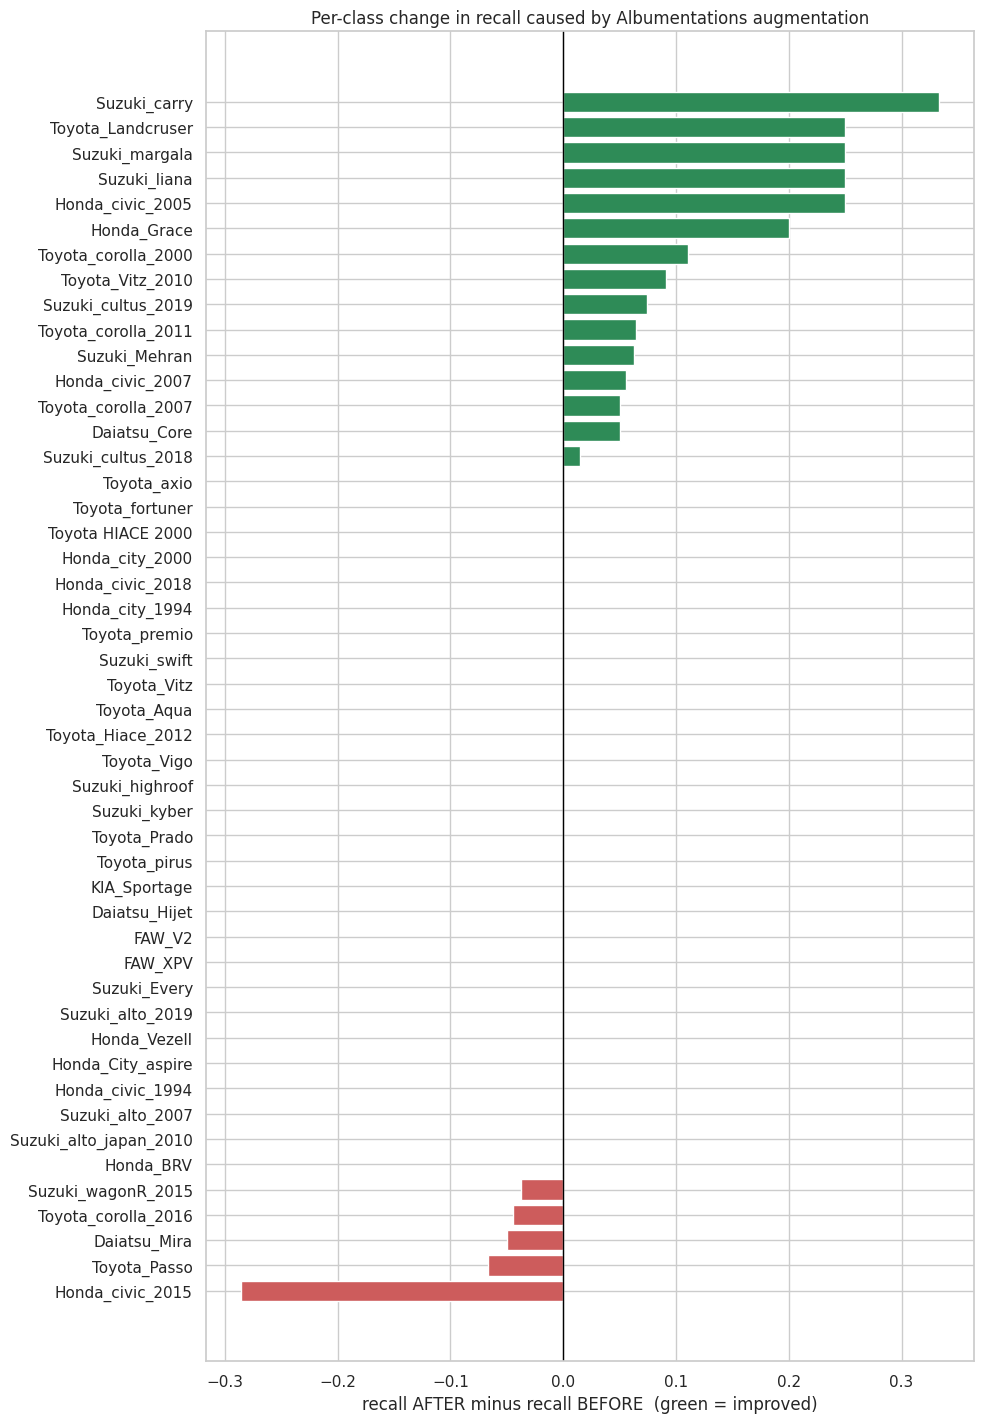

In [ ]:
# =====================================================================
# 9.2 PER-CLASS: WHICH CLASSES IMPROVED OR GOT WORSE?
# =====================================================================
errors_b = np.bincount(yt[wrong_b], minlength=N_CLASSES)
errors_a = np.bincount(yt[wrong_a], minlength=N_CLASSES)
support = np.bincount(yt, minlength=N_CLASSES)
median_count = np.median(TRAIN_COUNTS)

per_class_cmp = pd.DataFrame({
    "class_name": CLASS_NAMES,
    "train_count": TRAIN_COUNTS,
    "group": np.where(TRAIN_COUNTS < median_count, "minority", "majority"),
    "test_support": support,
    "errors_before": errors_b,
    "errors_after": errors_a,
    "recall_before": np.divide(support - errors_b, support, out=np.zeros(N_CLASSES), where=support > 0),
    "recall_after": np.divide(support - errors_a, support, out=np.zeros(N_CLASSES), where=support > 0),
})
per_class_cmp["errors_removed"] = per_class_cmp["errors_before"] - per_class_cmp["errors_after"]
per_class_cmp["recall_change"] = per_class_cmp["recall_after"] - per_class_cmp["recall_before"]
per_class_cmp = per_class_cmp.sort_values("recall_change", ascending=False).reset_index(drop=True)
per_class_cmp.to_csv(WORK / "07_per_class_before_after.csv", index=False)
display(per_class_cmp.round(4))

# minority vs majority summary
grp = per_class_cmp.groupby("group").agg(classes=("class_name", "count"), test_images=("test_support", "sum"),
                                         errors_before=("errors_before", "sum"), errors_after=("errors_after", "sum"))
grp["error_rate_before"] = grp["errors_before"] / grp["test_images"]
grp["error_rate_after"] = grp["errors_after"] / grp["test_images"]
print("\nMinority classes (fewer training images than the median class) vs majority classes:")
display(grp.round(4))

# bar chart of recall change per class
plot_df = per_class_cmp.sort_values("recall_change")
fig, ax = plt.subplots(figsize=(10, max(4, 0.3 * N_CLASSES)))
ax.barh(plot_df["class_name"], plot_df["recall_change"],
        color=np.where(plot_df["recall_change"] >= 0, "seagreen", "indianred"))
ax.axvline(0, c="black", lw=1)
ax.set_xlabel("recall AFTER minus recall BEFORE  (green = improved)")
ax.set_title("Per-class change in recall caused by Albumentations augmentation")
fig.tight_layout(); fig.savefig(WORK / "08_recall_change_per_class.png", dpi=150); plt.show()

Most frequent confusions (negative change = fewer mistakes after augmentation):


,true_class,predicted_as,mistakes_before,mistakes_after,change
0,Suzuki_alto_2019,Suzuki_alto_2007,2,3,1
1,Suzuki_carry,Suzuki_highroof,2,2,0
2,Honda_Grace,Honda_civic_2015,2,2,0
3,Honda_civic_2005,Honda_city_2000,3,0,-3
4,Toyota_corolla_2007,Toyota_corolla_2011,2,1,-1
5,Suzuki_cultus_2019,Daiatsu_Mira,3,0,-3
6,Toyota_Aqua,Toyota_Vitz,2,1,-1
7,Toyota_premio,Toyota_pirus,2,1,-1
8,Toyota_corolla_2007,Toyota_premio,1,2,1
9,Suzuki_alto_2019,Daiatsu_Mira,2,1,-1


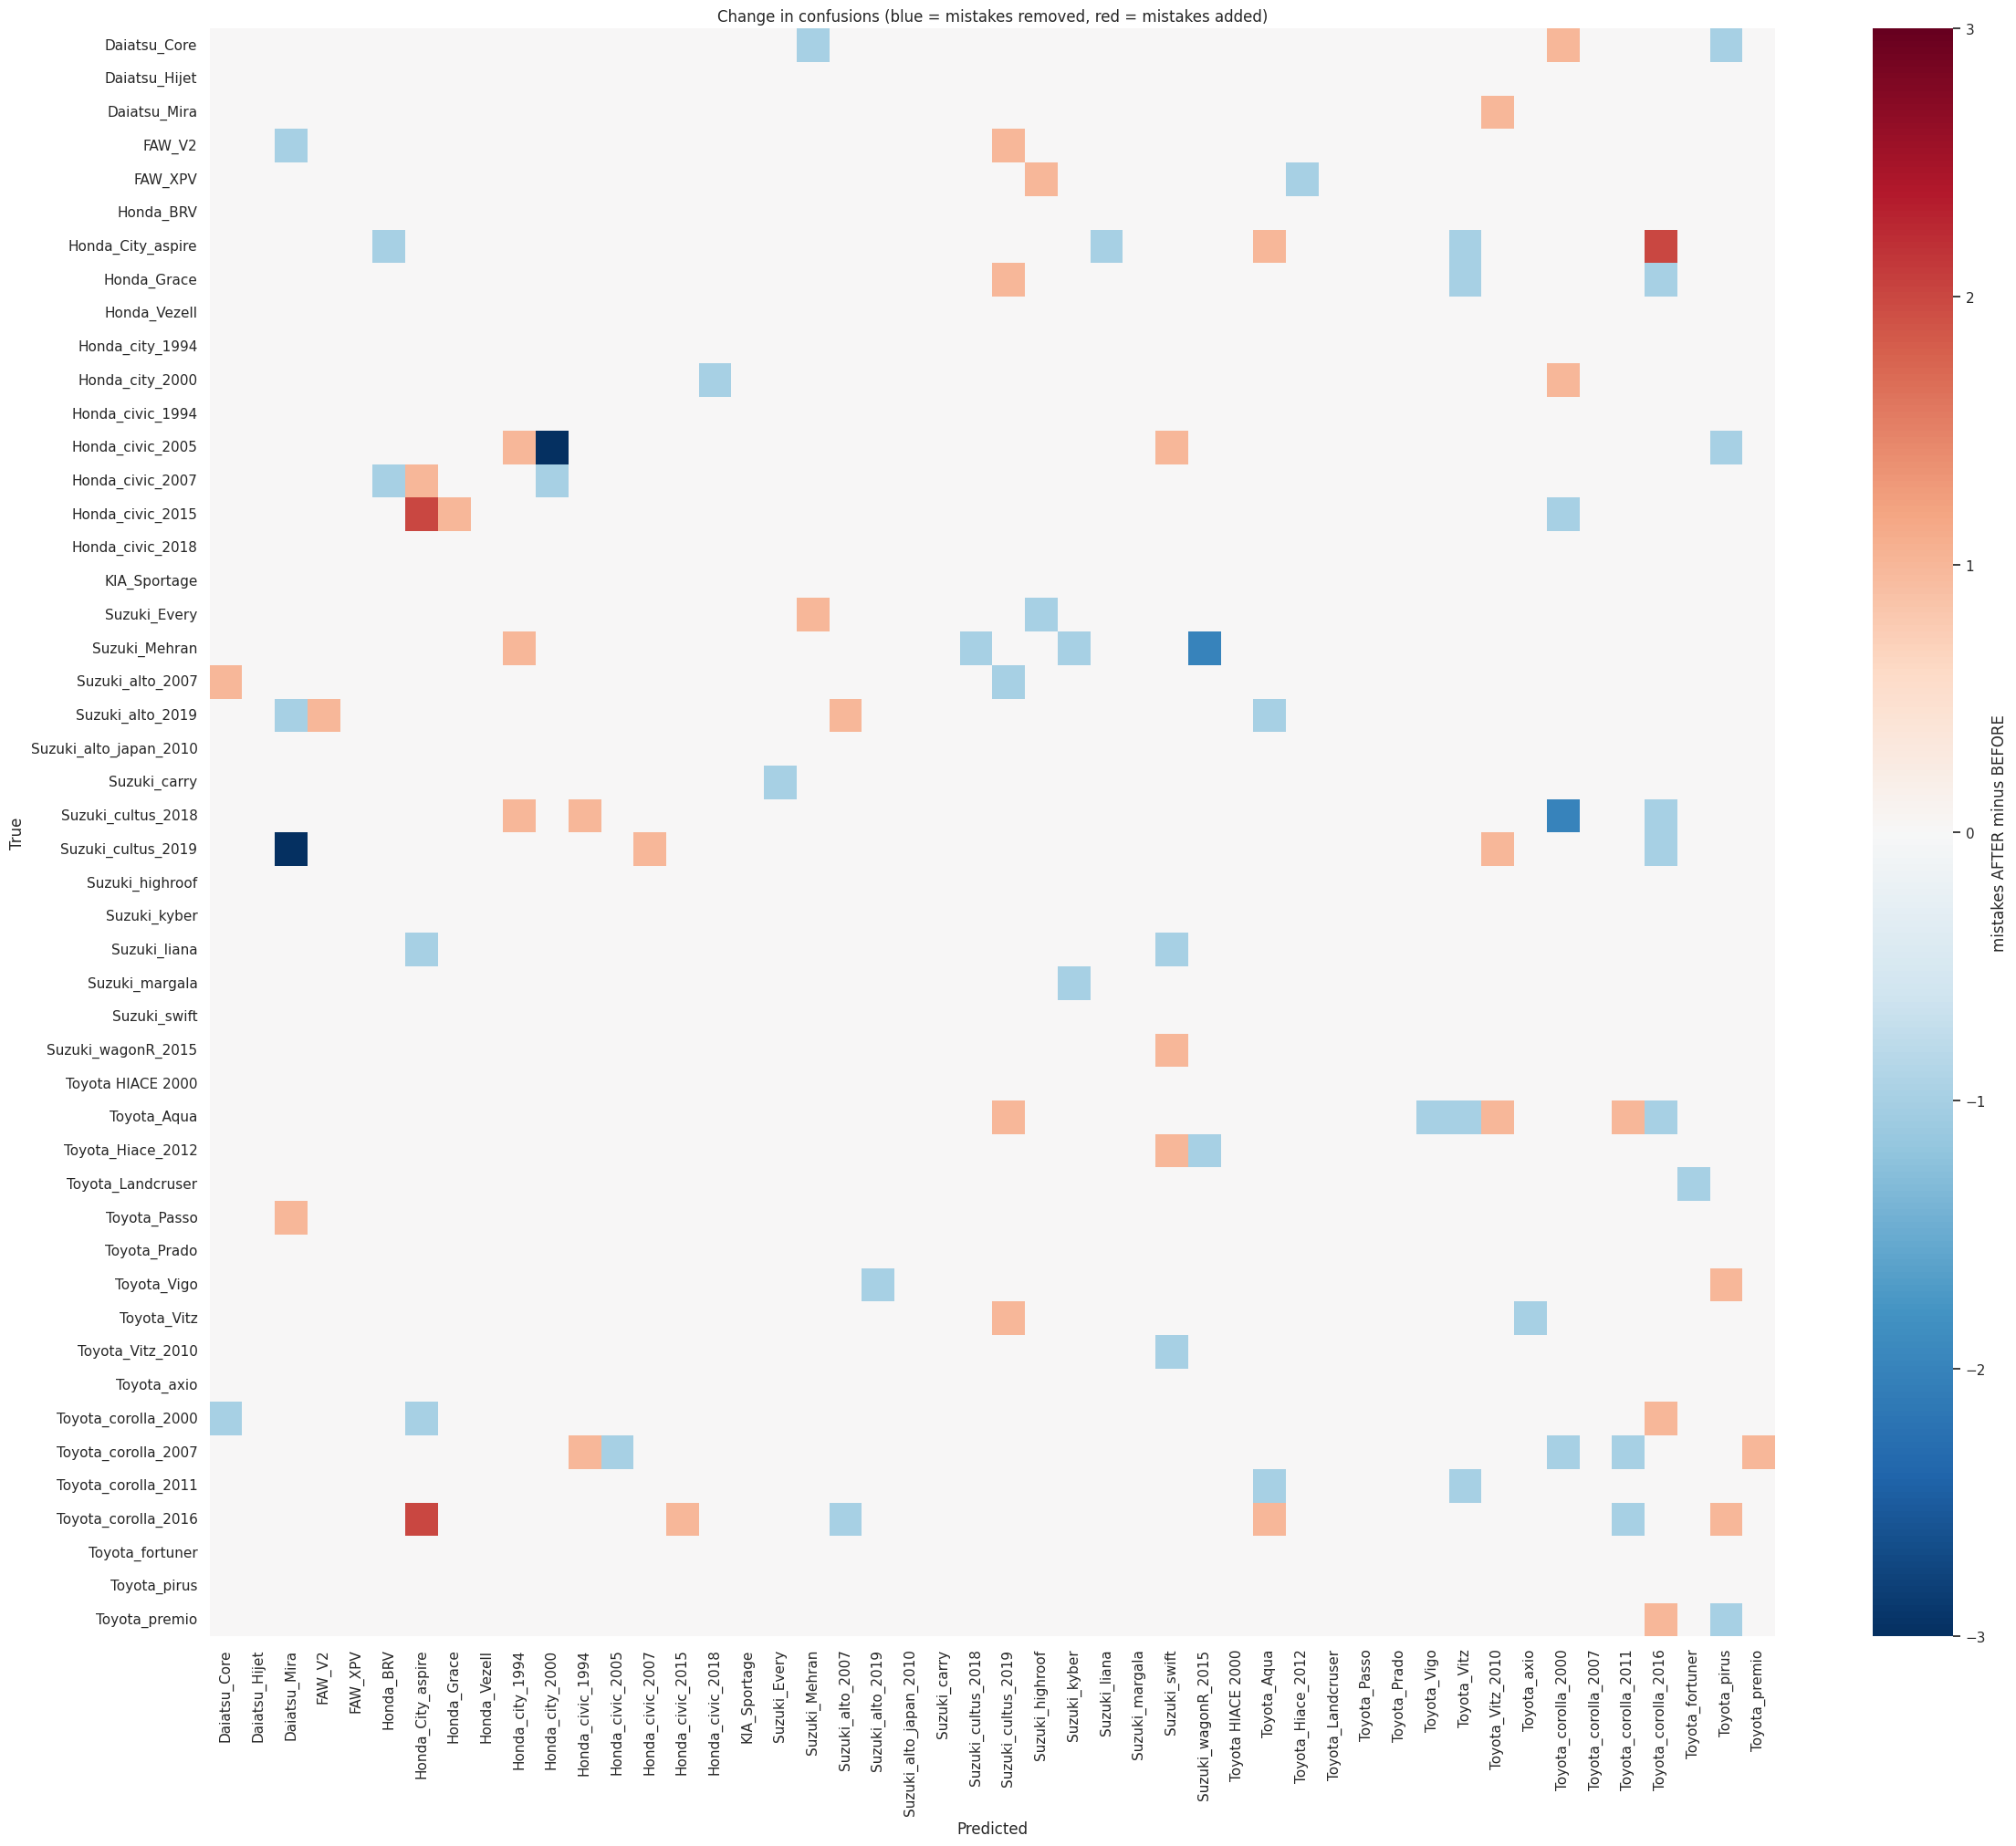

In [ ]:
# =====================================================================
# 9.3 WHICH CLASS PAIRS WERE CONFUSED BEFORE vs AFTER?
# =====================================================================
mB, mA = RESULTS[BEFORE]["matrix"].copy(), RESULTS[AFTER]["matrix"].copy()
np.fill_diagonal(mB, 0); np.fill_diagonal(mA, 0)          # keep only mistakes

def top_pairs(m, k=10):
    order = np.argsort(m, axis=None)[::-1][:k]
    return {(i, j) for i, j in zip(*np.unravel_index(order, m.shape)) if m[i, j] > 0}

pairs = sorted(top_pairs(mB) | top_pairs(mA), key=lambda p: -(mB[p] + mA[p]))
pair_df = pd.DataFrame({
    "true_class": [CLASS_NAMES[i] for i, _ in pairs],
    "predicted_as": [CLASS_NAMES[j] for _, j in pairs],
    "mistakes_before": [int(mB[p]) for p in pairs],
    "mistakes_after": [int(mA[p]) for p in pairs],
})
pair_df["change"] = pair_df["mistakes_after"] - pair_df["mistakes_before"]
pair_df.to_csv(WORK / "09_top_confusions_before_after.csv", index=False)
print("Most frequent confusions (negative change = fewer mistakes after augmentation):")
display(pair_df)

# heat-map of the change in every (true -> predicted) mistake cell
diff = mA - mB
lim = max(1, np.abs(diff).max())
side = max(8, 0.5 * N_CLASSES)
fig, ax = plt.subplots(figsize=(side, side * 0.85))
sns.heatmap(diff, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap="RdBu_r", center=0, vmin=-lim, vmax=lim,
            annot=N_CLASSES <= 15, fmt="d", ax=ax, cbar_kws={"label": "mistakes AFTER minus BEFORE"})
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Change in confusions (blue = mistakes removed, red = mistakes added)")
plt.setp(ax.get_xticklabels(), rotation=90)
fig.tight_layout(); fig.savefig(WORK / "10_confusion_difference.png", dpi=150, bbox_inches="tight"); plt.show()

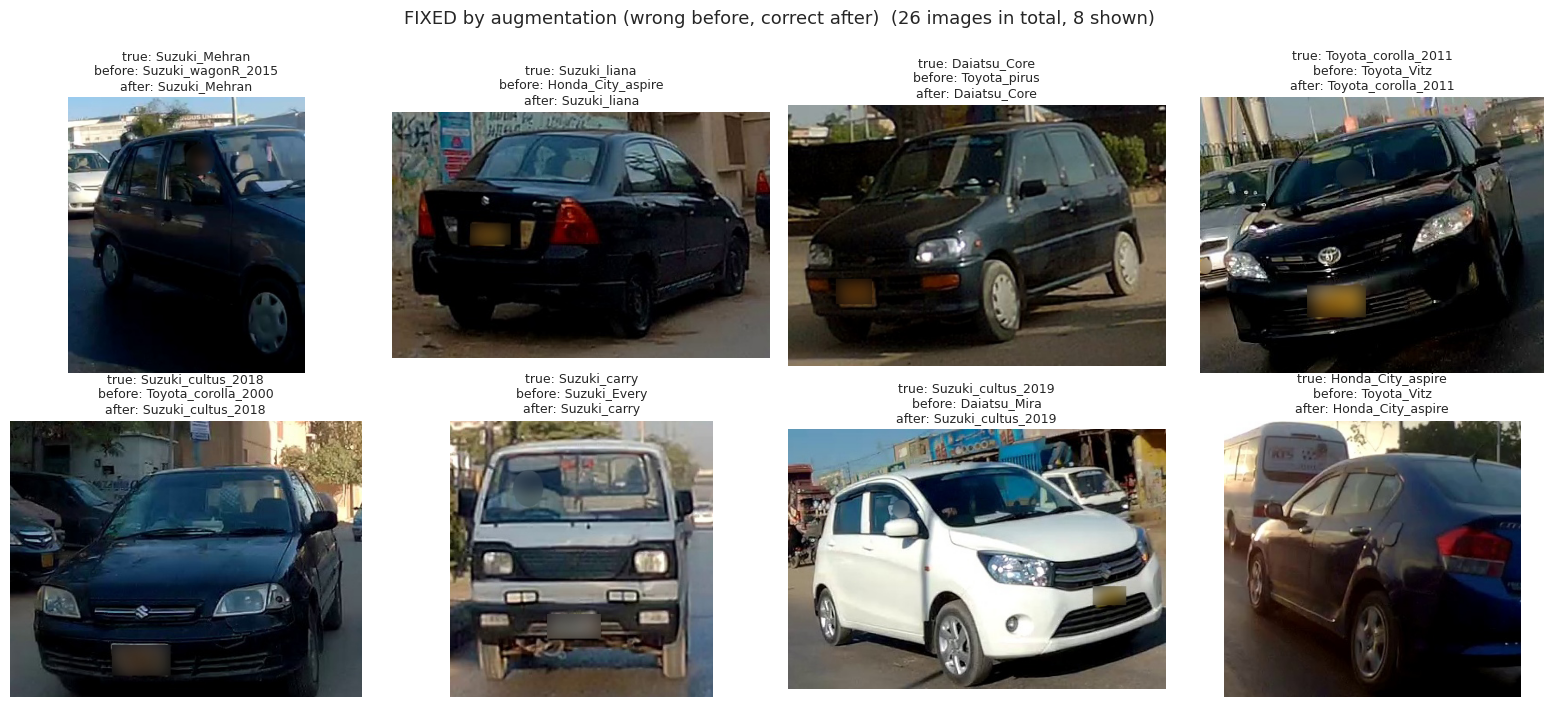

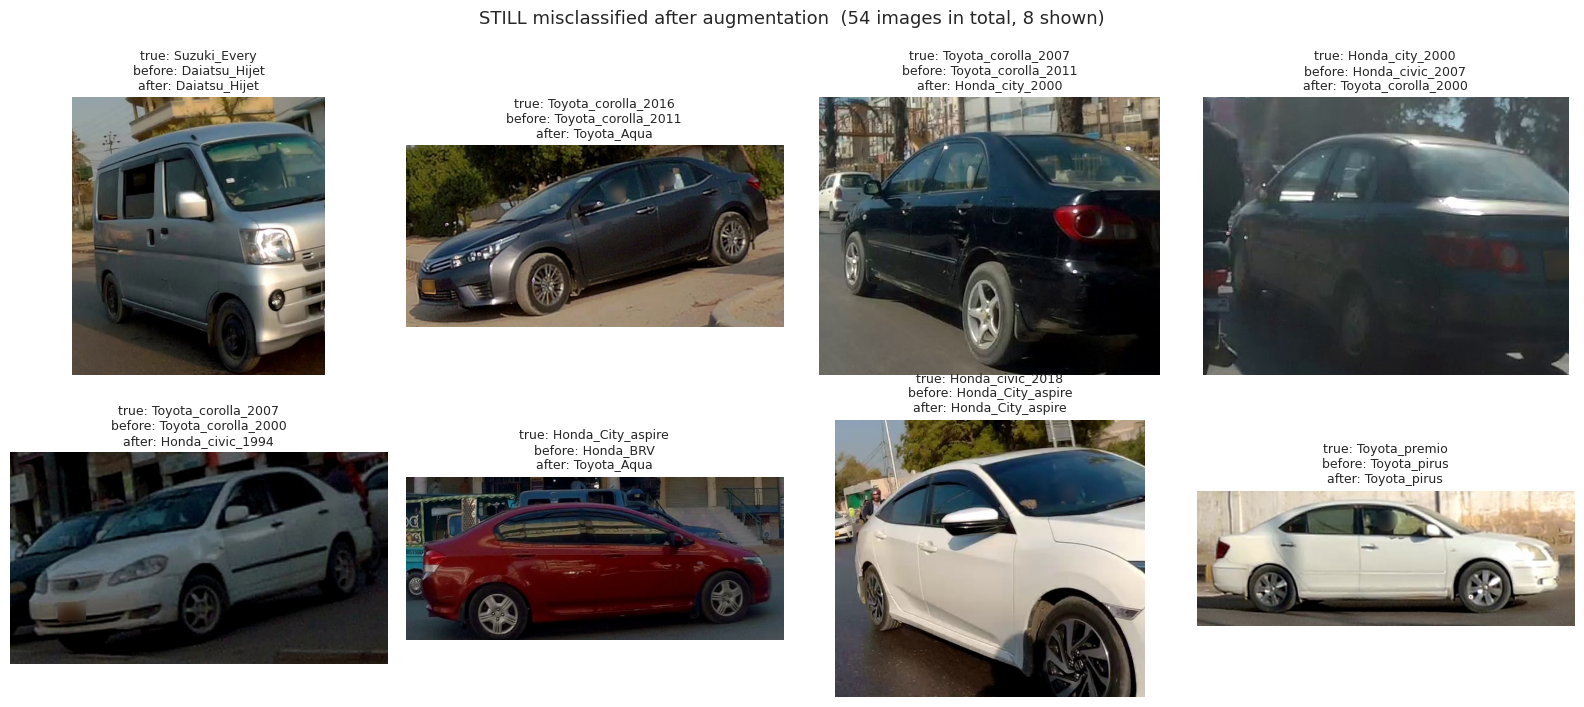

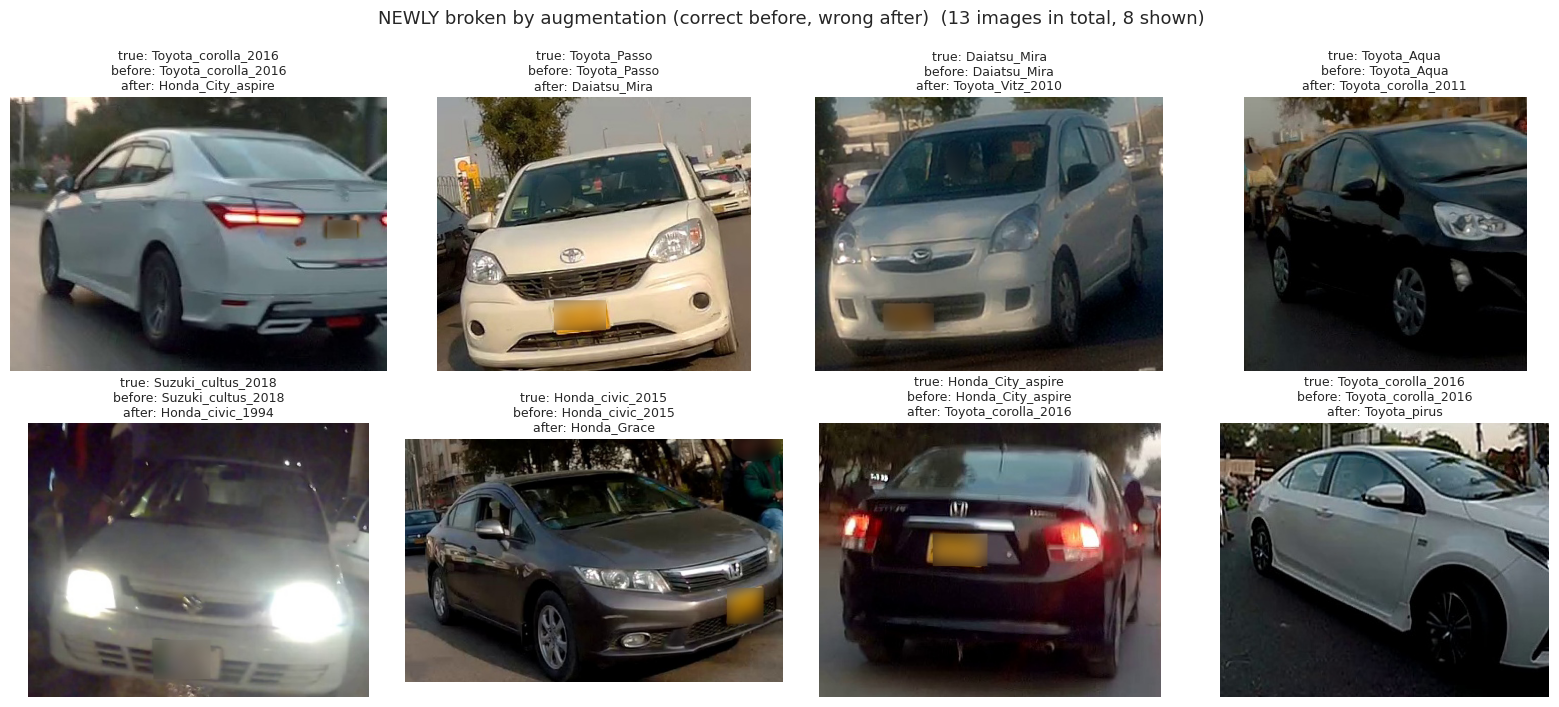

In [ ]:
# =====================================================================
# 9.4 VISUAL PROOF: ACTUAL IMAGES FIXED / STILL WRONG / NEWLY BROKEN
# =====================================================================
def show_gallery(mask, title, filename, max_images=8, seed=SEED):
    idx = np.where(mask)[0]
    if len(idx) == 0:
        print(f"{title}: none")
        return
    idx = np.random.RandomState(seed).choice(idx, size=min(max_images, len(idx)), replace=False)
    cols = min(4, len(idx)); rows_n = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(4 * cols, 3.6 * rows_n), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), idx):
        ax.imshow(Image.open(DATA["test_paths"][i]).convert("RGB"))
        ax.set_title(f"true: {CLASS_NAMES[yt[i]]}\nbefore: {CLASS_NAMES[pb[i]]}\nafter: {CLASS_NAMES[pa[i]]}", fontsize=9)
    fig.suptitle(f"{title}  ({int(mask.sum())} images in total, {len(idx)} shown)", fontsize=13)
    fig.tight_layout(); fig.savefig(WORK / filename, dpi=130, bbox_inches="tight"); plt.show()

show_gallery(fixed,       "FIXED by augmentation (wrong before, correct after)", "11_gallery_fixed.png")
show_gallery(still_wrong, "STILL misclassified after augmentation",              "12_gallery_still_wrong.png")
show_gallery(broken,      "NEWLY broken by augmentation (correct before, wrong after)", "13_gallery_broken.png")

---
## 10. Conclusion and export
The next cell writes an evidence-based verdict from the numbers above (it adapts to whatever the runs produced,
so the conclusion is never hard-coded), then packages every figure, table and the final model into one zip.

In [ ]:
# =====================================================================
# 10. AUTOMATIC VERDICT
# =====================================================================
mb, ma, ma_A = RESULTS[BEFORE]["metrics"], RESULTS[AFTER]["metrics"], RESULTS["A_no_aug_imbalanced"]["metrics"]
err_b, err_a = int(wrong_b.sum()), int(wrong_a.sum())

if err_a < err_b and p_value < 0.05:
    verdict = "YES: augmentation significantly reduced misclassifications."
elif err_a < err_b:
    verdict = "PARTLY: augmentation reduced misclassifications, but the gain is within random variation (not significant)."
elif err_a == err_b:
    verdict = "NO CHANGE: augmentation left the number of misclassifications unchanged."
else:
    verdict = "NO: augmentation did not help on this test set (more errors than before)."

lines = [
    "=" * 78,
    "FINAL VERDICT",
    "=" * 78,
    f"Transfer learning     : ON  ({PRETRAINED_SOURCE})",
    f"Balancing check       : imbalance {TRAIN_COUNTS.max() / TRAIN_COUNTS.min():.1f}x -> {balanced_counts.max() / max(balanced_counts.min(), 1):.2f}x per epoch with sampler",
    "",
    f"A imbalanced, no aug  : acc {ma_A['test_acc']:.4f} | macro-F1 {ma_A['test_macro_f1']:.4f}",
    f"B balanced, no aug    : acc {mb['test_acc']:.4f} | macro-F1 {mb['test_macro_f1']:.4f} | errors {err_b}",
    f"C balanced + aug      : acc {ma['test_acc']:.4f} | macro-F1 {ma['test_macro_f1']:.4f} | errors {err_a}",
    "",
    f"Misclassifications    : {err_b} -> {err_a}  (net {err_b - err_a:+d}; fixed {n_fixed}, newly broken {n_broken})",
    f"Accuracy change       : {100 * (ma['test_acc'] - mb['test_acc']):+.2f} points",
    f"Macro-F1 change       : {100 * (ma['test_macro_f1'] - mb['test_macro_f1']):+.2f} points",
    f"McNemar p-value       : {p_value:.4f}",
    "",
    f"Were errors fixed?    : {verdict}",
]
if "minority" in grp.index:
    g = grp.loc["minority"]
    lines.append(f"Minority classes      : error rate {g['error_rate_before']:.3f} -> {g['error_rate_after']:.3f}")
if err_a >= err_b:
    lines += ["", "Suggestions: more training data for the rarest classes, a longer stage 2 (UNFREEZE_FROM lower),",
                  "or milder augmentation if 'newly broken' images show augmentation-induced confusion."]
lines.append("=" * 78)
VERDICT_TEXT = "\n".join(lines)
print(VERDICT_TEXT)
(WORK / "FINAL_VERDICT.txt").write_text(VERDICT_TEXT)

FINAL VERDICT
Transfer learning     : ON  (local file: /kaggle/input/models/muhammadghulamabbas/mobilenet-v2/pytorch/default/1/mobilenet_v2-b0353104.pth)
Balancing check       : imbalance 20.8x -> 1.84x per epoch with sampler

A imbalanced, no aug  : acc 0.9041 | macro-F1 0.8561
B balanced, no aug    : acc 0.8935 | macro-F1 0.8439 | errors 80
C balanced + aug      : acc 0.9108 | macro-F1 0.8792 | errors 67

Misclassifications    : 80 -> 67  (net +13; fixed 26, newly broken 13)
Accuracy change       : +1.73 points
Macro-F1 change       : +3.53 points
McNemar p-value       : 0.0533

Were errors fixed?    : PARTLY: augmentation reduced misclassifications, but the gain is within random variation (not significant).
Minority classes      : error rate 0.190 -> 0.143


1006

In [ ]:
# =====================================================================
# 10. EXPORT: final model + zip of all results
# =====================================================================
# Pick the deployable model by VALIDATION macro-F1 (never by test results)
final_name = max((BEFORE, AFTER), key=lambda n: RESULTS[n]["best_val_f1"])
final_path = WORK / "vehicle_mobilenetv2_final.pt"
shutil.copy(WORK / f"best_{final_name}.pt", final_path)
(WORK / "class_names.json").write_text(json.dumps(CLASS_NAMES, indent=2))
print(f"Final model: {final_name} (best validation macro-F1 {RESULTS[final_name]['best_val_f1']:.4f}) -> {final_path.name}")

zip_path = WORK / "results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(WORK.iterdir()):
        if f.is_file() and f != zip_path and not f.name.startswith("best_"):
            z.write(f, f.name)
print(f"Saved {zip_path.name}  ({zip_path.stat().st_size / 1e6:.1f} MB)  with {len(zipfile.ZipFile(zip_path).namelist())} files")

# ---- how to reload the model later ----
# model = models.mobilenet_v2(weights=None)
# model.classifier = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(1280, len(CLASS_NAMES)))
# model.load_state_dict(torch.load("vehicle_mobilenetv2_final.pt", map_location="cpu")); model.eval()

Final model: C_aug_balanced (best validation macro-F1 0.9163) -> vehicle_mobilenetv2_final.pt
Saved results.zip  (24.2 MB)  with 36 files
